# GhostDemand AI · improved model-training notebook

**A guided, runnable revision of `training (1).ipynb` · 28 October 2026**

## Goal
Train and evaluate the six blocker labels used by the application, extract a few
commercial fields safely, retrieve candidate SKUs, explore demand clusters, and
export a model plus a local inference API. The complete default path runs on CPU
without downloading a transformer or needing the original public datasets.

**Practice data are synthetic.** Saved example scores show a working experiment,
not accuracy on real customers. Nothing here connects to WhatsApp/email accounts,
writes to the application's database, or replaces its active model.

### What changed from your original notebook
| Original issue | Improvement |
|---|---|
| Eight training examples and no holdout evaluation | Embedded 108-example starter, grouped train/validation/test split, dummy baseline, macro F1 and error analysis |
| Four invented intent names | Exact six GhostDemand blocker labels |
| ESCI source IDs and catalog descriptions mixed with requests | Separate source contracts; no fallback to “first column” |
| Availability questions treated as proof of a lost sale | Explicit eligibility gate; unknown/pending requests defer |
| Prices/specifications mistaken for quantity | Conservative raw-text extraction with regression examples |
| Encoder loading called “training” | Pretrained encoding, supervised training and unsupervised clustering are distinguished |
| Empty evaluation/deployment sections | Executable metrics, reload checks, export, API smoke tests and rollout instructions |

Run **Restart kernel → Run all**. Each numbered section explains the purpose,
input, expected output and next check. Optional transformer cells print a clear
skip message until you enable their flags.
Expand the collapsed supporting cells to inspect the embedded data or generated
API source; the main training/evaluation code remains visible.

## Setup
### 1. Choose your inputs and optional experiments

Set `LABELED_REQUESTS_CSV` only when you have reviewed request/reason records.
Leave it as `None` for the embedded practice data. Public data are inspected for
their actual purpose; they are never silently assigned blocker labels.

On Colab, upload input files to the runtime and set `PUBLIC_DATA_DIR` to that
folder. On a local checkout, this cell recognizes the GhostDemand folder and
its parent Downloads folder. Output stays in a separate learning directory.

In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

SEED = 42
LABELED_REQUESTS_CSV = None       # e.g. Path('/content/reviewed_requests.csv')
SPLIT_STRATEGY = 'grouped'        # 'chronological' requires real timezone-aware decision times
INSTALL_MISSING_CORE = True
INSPECT_PUBLIC_DATA = True
RUN_SETFIT = False               # supervised transformer fine-tuning; optional download
RUN_SEMANTIC = False             # pretrained MiniLM retrieval/clustering; no fine-tuning
DOWNLOAD_EXPORT_IN_COLAB = False
TARGET_ACCEPTED_ACCURACY = 0.90  # validation observation, not a service-level guarantee
MIN_ACCEPTED_VALIDATION = 5

PROJECT_ROOT = next((p for p in [Path.cwd(), *list(Path.cwd().parents)[:3]]
                     if (p/'training_data.json').exists() and (p/'demand_ml.py').exists()), None)
PUBLIC_DATA_DIR = PROJECT_ROOT.parent if PROJECT_ROOT else Path.cwd()
OUTPUT_DIR = Path.cwd()/'ghostdemand_training_output'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT_DIR/'.matplotlib'))

requirements = {
    'numpy': 'numpy>=1.26,<3', 'pandas': 'pandas>=2.2,<4',
    'sklearn': 'scikit-learn>=1.5,<2', 'matplotlib': 'matplotlib>=3.8,<4',
    'flask': 'Flask>=3,<4', 'openpyxl': 'openpyxl>=3.1,<4',
}
from importlib.metadata import version as installed_version, PackageNotFoundError
from packaging.requirements import Requirement
missing = []
for module, requirement in requirements.items():
    parsed = Requirement(requirement)
    try:
        compatible = importlib.util.find_spec(module) is not None and installed_version(parsed.name) in parsed.specifier
    except PackageNotFoundError:
        compatible = False
    if not compatible:
        missing.append(requirement)
if missing:
    if not INSTALL_MISSING_CORE:
        raise RuntimeError('Install these packages in this kernel: ' + ' '.join(missing))
    restart_required = any(module in sys.modules and requirement in missing for module,requirement in requirements.items())
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
    if restart_required:
        raise RuntimeError('Packages changed after import. Restart the kernel, then Run all again.')
print('Output directory:', OUTPUT_DIR)
print('Optional transformer training:', RUN_SETFIT, '| pretrained semantic encoding:', RUN_SEMANTIC)

Output directory: /Users/dengachiek/Downloads/GhostDemand/notebooks/ghostdemand_training_output
Optional transformer training: False | pretrained semantic encoding: False


### 2. Import the core tools and set a common plotting style

The default classifier is character TF-IDF plus logistic regression. Its features
and numeric JSON artifact match the existing application. No `spacy`, word cloud,
GPU or transformer package is required for this default path.

In [2]:
import csv
import hashlib
import json
import math
import platform
import re
import time
import unicodedata
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from importlib.metadata import version
from typing import Optional
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, silhouette_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize

get_ipython().run_line_magic('matplotlib', 'inline')

np.random.seed(SEED)
BLUE, GOLD, INK, GRAY = '#3657A7', '#A46B13', '#192B49', '#627087'
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 115,
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': INK, 'text.color': INK, 'savefig.bbox': 'tight'})

REASON_LABELS = tuple(sorted(['out_of_stock', 'price_too_high', 'not_stocked',
                             'quote_rejected', 'lead_time', 'abandoned']))
VECTORIZER_PARAMS = dict(analyzer='char_wb', ngram_range=(3, 5),
                         sublinear_tf=True, max_features=6000)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n', encoding='utf-8')

def normalized_key(text):
    return ' '.join(re.sub(r'[^\w\s]', ' ', unicodedata.normalize('NFKC', text).casefold()).split())

def sha256_file(path):
    hasher = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            hasher.update(chunk)
    return hasher.hexdigest()

environment = {name: version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'Flask']}
environment['python'] = platform.python_version()
display(pd.Series(environment, name='Version').to_frame())

,Version
numpy,2.3.5
pandas,2.2.3
scikit-learn,1.9.1
matplotlib,3.11.2
Flask,3.1.3
python,3.12.14


## Steps
### 3. Keep datasets and business meanings separate

| Source | Correct use | What it cannot establish |
|---|---|---|
| Reviewed GhostDemand requests | Train six blocker labels | An unreviewed prediction is not ground truth |
| [Bitext retail/e-commerce](https://huggingface.co/datasets/bitext/Bitext-retail-ecommerce-llm-chatbot-training-dataset) | Retail-language/intent exploration and annotation queue | A support question does not establish a failed sale; this source is hybrid synthetic |
| [Amazon ESCI](https://github.com/amazon-science/esci-data) examples + products | Query/product relevance matching | `sources.csv` contains IDs/source names, not query strings or failure reasons |
| [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) | Historical completed-sales forecasting practice | Product descriptions are not unsuccessful customer conversations |

The inspection below reads source schemas/counts and a bounded workbook preview.
It never trains a loss classifier from these unverified meanings. Declared source
licenses: Bitext CDLA-Sharing-1.0; ESCI repository Apache-2.0; UCI CC BY 4.0.
Retain publisher terms/readmes and attribution when using their data.

In [3]:
public_sources = []
if INSPECT_PUBLIC_DATA:
    bitext_path = PUBLIC_DATA_DIR/'bitext-retail-ecommerce-llm-chatbot-training-dataset.csv'
    if bitext_path.exists():
        bitext = pd.read_csv(bitext_path, usecols=['instruction', 'intent', 'category'])
        assert {'instruction', 'intent', 'category'} <= set(bitext)
        public_sources.append(dict(dataset='Bitext', rows=len(bitext), purpose='Auxiliary language/intent only',
                                   file_sha256=sha256_file(bitext_path)))
        print('Bitext:', len(bitext), 'rows;', bitext.intent.nunique(), 'intents;',
              bitext.category.nunique(), 'categories. No blocker labels inferred.')
        display(bitext.groupby('intent').size().rename('Rows').sort_values().head(8).to_frame())
        # Balanced intent sampling avoids the original sorted head(100) bias.
        annotation_queue = (bitext.groupby('intent', group_keys=False)
                            .sample(n=2, random_state=SEED).copy())
        annotation_queue = annotation_queue.rename(columns={'instruction':'text','intent':'original_intent'})
        annotation_queue['id'] = ['bitext-'+str(index) for index in annotation_queue.index]
        annotation_queue['source'] = 'bitext_synthetic_chatbot'
        annotation_queue['conversation_id'] = annotation_queue['id']
        annotation_queue['group_id'] = 'REVIEW-ME-TEMPLATE-FAMILY'
        annotation_queue['captured_at'] = ''
        annotation_queue['origin'] = 'bitext_hybrid_synthetic'
        annotation_queue['is_synthetic'] = 1
        annotation_queue['eligibility'] = ''
        annotation_queue['reason'] = ''
        annotation_queue['verified'] = 0
        annotation_queue.to_csv(OUTPUT_DIR/'bitext_annotation_queue.csv', index=False)
    else:
        print('Bitext not present. Upload the publisher CSV to PUBLIC_DATA_DIR for optional inspection.')

    sources_path = PUBLIC_DATA_DIR/'shopping_queries_dataset_sources.csv'
    if sources_path.exists():
        sources = pd.read_csv(sources_path)
        assert {'query_id', 'source'} <= set(sources)
        print('ESCI sources metadata:', len(sources), 'rows; columns:', sources.columns.tolist())
        print('This file has NO query text. Get examples.parquet and products.parquet for matching.')
        public_sources.append(dict(dataset='ESCI source metadata', rows=len(sources),
                                   purpose='Metadata only; excluded from text training', file_sha256=sha256_file(sources_path)))

    retail_path = PUBLIC_DATA_DIR/'online_retail_II.xlsx'
    if retail_path.exists():
        retail_preview = pd.read_excel(retail_path, nrows=8)
        print('Online Retail II preview columns:', retail_preview.columns.tolist())
        print('Transaction/catalog data are reserved for sales forecasting, not blocker labels.')
        public_sources.append(dict(dataset='UCI Online Retail II', preview_rows=len(retail_preview),
                                   purpose='Sales forecasting only', file_sha256=sha256_file(retail_path)))
else:
    print('Optional public-data inspection disabled. Embedded practice data still work.')
save_json(OUTPUT_DIR/'public_source_manifest.json', public_sources)

Bitext: 44884 rows; 46 intents; 13 categories. No blocker labels inferred.


,Rows
intent,
missing_item,721
availability_in_store,756
delivery_time,920
store_location,924
add_product,957
request_refund,957
change_order,961
availability,972


ESCI sources metadata: 130652 rows; columns: ['query_id', 'source']
This file has NO query text. Get examples.parquet and products.parquet for matching.


Online Retail II preview columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Transaction/catalog data are reserved for sales forecasting, not blocker labels.


### 4. Define the blocker target and input contract

Only run a blocker classifier on a **confirmed unmet request**. An ordinary
availability question is `pending` until context proves unavailability. A cart
help question is not a blocker label. Split multi-product cases before labeling.

For real data supply a CSV with `id,text,reason,source,conversation_id,group_id,
captured_at,origin,is_synthetic,verified,eligibility`. `verified=1` means the label
has been reviewed; `is_synthetic` is 0/1; `eligibility=confirmed_unmet` is required
for this training task. Keep names/phones/order references minimized locally.
Use timezone-aware timestamps when available. Missing dates remain missing.
For this task, prediction happens when the failed-request context is available;
`captured_at` should describe that decision time. Do not include later order or
follow-up outcomes in the text features.

| Label | Evidence |
|---|---|
| `out_of_stock` | Store carries the product but has no inventory |
| `not_stocked` | Requested product is outside the store's range |
| `price_too_high` | Price explicitly prevents the purchase |
| `quote_rejected` | A quotation was explicitly declined/lost |
| `lead_time` | Delivery/availability misses the customer's deadline |
| `abandoned` | A defined inactivity/follow-up window elapsed without response |

Define a primary-blocker policy for overlapping reasons and send ambiguous cases
to a reviewer. Preserve `not_stocked` vs `out_of_stock`; they imply different
business actions. The following embedded examples are for learning, not real logs.
Underspecified questions/discount requests in the old synthetic starter are
clarified in this notebook copy so the text includes the actual failed-sale
context; the repository's original starter file is unchanged. Synthetic
`abandoned` examples assume the business's inactivity policy has elapsed. Real
labels must record that evidence and prediction-time context explicitly.

In [4]:
STARTER_EXAMPLES = [
    {"text": "The cement bags are out of stock today", "reason": "out_of_stock"},
    {"text": "All our solar panels have sold out", "reason": "out_of_stock"},
    {"text": "We ran out of waterproof boots this morning", "reason": "out_of_stock"},
    {"text": "No inventory left for the requested water pump", "reason": "out_of_stock"},
    {"text": "The last carton of tiles was already sold", "reason": "out_of_stock"},
    {"text": "Our shelves are empty and a restock is needed", "reason": "out_of_stock"},
    {"text": "The customer wanted rebar but our stock was depleted", "reason": "out_of_stock"},
    {"text": "We normally carry this paint but have none left", "reason": "out_of_stock"},
    {"text": "The warehouse has zero units of the requested heater", "reason": "out_of_stock"},
    {"text": "The item is temporarily unavailable until replenishment", "reason": "out_of_stock"},
    {"text": "Another buyer took the remaining stock of batteries", "reason": "out_of_stock"},
    {"text": "We could not supply the order because inventory is exhausted", "reason": "out_of_stock"},
    {"text": "The cement is too expensive for my budget", "reason": "price_too_high"},
    {"text": "The shopper could not buy the solar panel at this price and needs a cheaper option", "reason": "price_too_high"},
    {"text": "Your price for boots is too high", "reason": "price_too_high"},
    {"text": "The buyer could not purchase the water pump unless its price was reduced", "reason": "price_too_high"},
    {"text": "I cannot afford the tiles at that price", "reason": "price_too_high"},
    {"text": "The quoted amount is over budget", "reason": "price_too_high"},
    {"text": "The customer would not purchase the rebar because it exceeded their budget", "reason": "price_too_high"},
    {"text": "The cost of paint exceeds what I can spend", "reason": "price_too_high"},
    {"text": "The heater is pricey and I need a more affordable option", "reason": "price_too_high"},
    {"text": "We lost the sale because our prices were unaffordable", "reason": "price_too_high"},
    {"text": "The battery costs more than the customer can pay", "reason": "price_too_high"},
    {"text": "The price was beyond the customer budget so the purchase did not proceed", "reason": "price_too_high"},
    {"text": "Customer requested white cement but we do not sell that product", "reason": "not_stocked"},
    {"text": "We do not carry solar water heaters in our range", "reason": "not_stocked"},
    {"text": "Customer needs waterproof work boots size 44 which our store does not carry", "reason": "not_stocked"},
    {"text": "The requested pump brand is outside our catalogue and we could not supply it", "reason": "not_stocked"},
    {"text": "Customer searched for tiles that we do not sell", "reason": "not_stocked"},
    {"text": "I need a product that is missing from your catalogue", "reason": "not_stocked"},
    {"text": "We have never stocked stainless steel rebar", "reason": "not_stocked"},
    {"text": "The shopper asked for purple exterior paint which is not in our product range", "reason": "not_stocked"},
    {"text": "A shopper asked for a brand we do not stock", "reason": "not_stocked"},
    {"text": "This item is outside our product range", "reason": "not_stocked"},
    {"text": "We could not supply the requested lithium batteries because we never carry them", "reason": "not_stocked"},
    {"text": "Requested fittings are not part of our assortment so we could not fulfil the request", "reason": "not_stocked"},
    {"text": "Customer rejected our quote and chose another supplier", "reason": "quote_rejected"},
    {"text": "The solar panel deal went to a competitor", "reason": "quote_rejected"},
    {"text": "Our tender for work boots was declined", "reason": "quote_rejected"},
    {"text": "Buyer went elsewhere after receiving the pump quotation", "reason": "quote_rejected"},
    {"text": "The customer accepted another vendor's proposal", "reason": "quote_rejected"},
    {"text": "We lost the bid to a competing business", "reason": "quote_rejected"},
    {"text": "The rebar quotation was turned down", "reason": "quote_rejected"},
    {"text": "They chose another company for the paint contract", "reason": "quote_rejected"},
    {"text": "The heater quote was not accepted by procurement", "reason": "quote_rejected"},
    {"text": "Client declined our offer and purchased elsewhere", "reason": "quote_rejected"},
    {"text": "Our battery proposal was unsuccessful", "reason": "quote_rejected"},
    {"text": "A rival supplier won the order after the quote review", "reason": "quote_rejected"},
    {"text": "Delivery of cement will take too long", "reason": "lead_time"},
    {"text": "I cannot wait three weeks for solar panels", "reason": "lead_time"},
    {"text": "The boots would arrive after our deadline", "reason": "lead_time"},
    {"text": "Your pump delivery time does not work for us", "reason": "lead_time"},
    {"text": "We need tiles tomorrow but shipping takes a month", "reason": "lead_time"},
    {"text": "The lead time is longer than the project schedule", "reason": "lead_time"},
    {"text": "Rebar cannot be delivered in time for the job", "reason": "lead_time"},
    {"text": "The paint shipment was delayed beyond the required date", "reason": "lead_time"},
    {"text": "When can you deliver the heater I cannot wait", "reason": "lead_time"},
    {"text": "Customer cancelled because delivery was too slow", "reason": "lead_time"},
    {"text": "Battery installation cannot happen soon enough", "reason": "lead_time"},
    {"text": "The earliest arrival date misses the construction deadline", "reason": "lead_time"},
    {"text": "The cement enquiry went quiet with no response", "reason": "abandoned"},
    {"text": "Customer never replied about the solar panels", "reason": "abandoned"},
    {"text": "Shopper left the boots in the cart and disappeared", "reason": "abandoned"},
    {"text": "The buyer abandoned the pump enquiry", "reason": "abandoned"},
    {"text": "No reply after we sent the tile details", "reason": "abandoned"},
    {"text": "The customer ghosted us after asking for more information", "reason": "abandoned"},
    {"text": "Rebar was added to a cart but checkout was never completed", "reason": "abandoned"},
    {"text": "The paint conversation stopped without a purchase", "reason": "abandoned"},
    {"text": "We followed up about the heater but heard nothing back", "reason": "abandoned"},
    {"text": "Customer left the chat before placing the order", "reason": "abandoned"},
    {"text": "The battery enquiry has had no response to follow ups", "reason": "abandoned"},
    {"text": "The shopper stopped responding and did not complete checkout", "reason": "abandoned"},
    {"text": "The wireless earbuds are sold out and the shelf is empty", "reason": "out_of_stock"},
    {"text": "We ran out of USB-C fast chargers before the shopper arrived", "reason": "out_of_stock"},
    {"text": "The requested running shoe size has zero units in inventory", "reason": "out_of_stock"},
    {"text": "Everyday backpacks are unavailable until our next restock", "reason": "out_of_stock"},
    {"text": "We normally sell insulated water bottles but have none left", "reason": "out_of_stock"},
    {"text": "Customer could not order the headphones because our stock was depleted", "reason": "out_of_stock"},
    {"text": "The wireless earbuds cost more than the customer can afford", "reason": "price_too_high"},
    {"text": "The USB-C charger is too expensive; can you lower the price", "reason": "price_too_high"},
    {"text": "My budget for running shoes is lower than your asking price", "reason": "price_too_high"},
    {"text": "The backpack price is too high and I need a cheaper option", "reason": "price_too_high"},
    {"text": "The insulated bottle exceeded the buyer budget so the sale could not proceed", "reason": "price_too_high"},
    {"text": "The total cost of the headphones is over my budget", "reason": "price_too_high"},
    {"text": "The requested noise cancelling wireless earbud model is not in our store range", "reason": "not_stocked"},
    {"text": "Looking for a charger brand that is missing from your catalogue", "reason": "not_stocked"},
    {"text": "Your shop does not sell the running shoe size I need", "reason": "not_stocked"},
    {"text": "Customer wants a waterproof laptop backpack but our store does not sell this type", "reason": "not_stocked"},
    {"text": "I searched for a thermal bottle that your store has never stocked", "reason": "not_stocked"},
    {"text": "Customer wants a headphone model outside our current assortment", "reason": "not_stocked"},
    {"text": "The wireless earbud quotation was rejected in favour of another seller", "reason": "quote_rejected"},
    {"text": "Customer chose a competitor after receiving our charger quote", "reason": "quote_rejected"},
    {"text": "The buyer declined our shoe offer and purchased elsewhere", "reason": "quote_rejected"},
    {"text": "Our proposal for the backpack order was turned down", "reason": "quote_rejected"},
    {"text": "A rival supplier won the quote for insulated water bottles", "reason": "quote_rejected"},
    {"text": "Procurement did not accept the headphone quotation", "reason": "quote_rejected"},
    {"text": "The earbuds would arrive after the customer travels", "reason": "lead_time"},
    {"text": "I need a charger tomorrow but your shipping takes a week", "reason": "lead_time"},
    {"text": "The running shoes cannot be delivered before my race deadline", "reason": "lead_time"},
    {"text": "A week is too long to wait for this backpack", "reason": "lead_time"},
    {"text": "The insulated bottle shipment was delayed beyond our event date", "reason": "lead_time"},
    {"text": "Customer cancelled the headphones because delivery was too slow", "reason": "lead_time"},
    {"text": "Customer left wireless earbuds in the cart and never checked out", "reason": "abandoned"},
    {"text": "The charger enquiry went quiet after we sent product details", "reason": "abandoned"},
    {"text": "No reply to our follow-up about the running shoes", "reason": "abandoned"},
    {"text": "The shopper abandoned the backpack conversation without ordering", "reason": "abandoned"},
    {"text": "Customer stopped responding after asking about an insulated bottle", "reason": "abandoned"},
    {"text": "Headphones were added to the basket but the purchase was never completed", "reason": "abandoned"}
]


if LABELED_REQUESTS_CSV is None:
    requests_df = pd.DataFrame(STARTER_EXAMPLES)
    requests_df['id'] = [f'starter-{i:03}' for i in range(len(requests_df))]
    requests_df['source'] = 'synthetic'
    requests_df['conversation_id'] = requests_df['id']
    requests_df['group_id'] = requests_df['id']  # conservative near-duplicate grouping is added below
    requests_df['captured_at'] = ''             # not invented as the execution time
    requests_df['origin'] = 'ghostdemand_synthetic_starter_clarified_v2'
    requests_df['is_synthetic'] = 1
    requests_df['verified'] = 1
    requests_df['eligibility'] = 'confirmed_unmet'
    data_origin = 'Embedded synthetic starter (108 examples; 13 ambiguous cases clarified)'
else:
    requests_df = pd.read_csv(LABELED_REQUESTS_CSV, dtype=str).fillna('')
    data_origin = str(LABELED_REQUESTS_CSV)

required = {'id','text','reason','source','conversation_id','group_id','captured_at',
            'origin','is_synthetic','verified','eligibility'}
missing_columns = required - set(requests_df)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}. Do not auto-label a public intent dataset.')
for column in required:
    requests_df[column] = requests_df[column].fillna('').astype(str)
    if column != 'text':
        requests_df[column] = requests_df[column].str.strip()
print(data_origin, '| rows:', len(requests_df))

Embedded synthetic starter (108 examples; 13 ambiguous cases clarified) | rows: 108


### 5. EDA: audit labels, origin, missingness and message length

The unit is one request context. Check whether repeats actually represent the
same conversation, whether a class/channel is missing, and whether label quality
matches the business definition. Balanced synthetic labels do not prove coverage
of actual WhatsApp, email, chatbot, sales notes or voice transcripts.

In [5]:
if requests_df.empty:
    raise ValueError('No labeled requests supplied.')
requests_df['normalized_key'] = requests_df.text.map(normalized_key)
requests_df['characters'] = requests_df.text.str.len()
requests_df['words'] = requests_df.text.str.split().str.len()
eda_summary = pd.DataFrame({'Missing or blank': (requests_df[list(sorted(required))] == '').sum()})
display(eda_summary)
display(requests_df.groupby(['origin','is_synthetic']).size().rename('Rows').to_frame())
label_counts = requests_df.reason.value_counts().reindex(REASON_LABELS, fill_value=0)
display(pd.DataFrame({'Rows': label_counts, 'Share': (label_counts/len(requests_df)).map('{:.1%}'.format)}))
print('Exact normalized duplicate rows:', int(requests_df.normalized_key.duplicated().sum()))
print('Conflicting normalized-text groups:', int(requests_df.groupby('normalized_key').reason.nunique().gt(1).sum()))
print('Date coverage:', int(requests_df.captured_at.ne('').sum()), '/', len(requests_df))
display(requests_df[['characters','words']].describe().round(1))

,Missing or blank
captured_at,108
conversation_id,0
eligibility,0
group_id,0
id,0
is_synthetic,0
origin,0
reason,0
source,0
text,0


,,Rows
origin,is_synthetic,
ghostdemand_synthetic_starter_clarified_v2,1,108


,Rows,Share
reason,,
abandoned,18,16.7%
lead_time,18,16.7%
not_stocked,18,16.7%
out_of_stock,18,16.7%
price_too_high,18,16.7%
quote_rejected,18,16.7%


Exact normalized duplicate rows: 0
Conflicting normalized-text groups: 0
Date coverage: 0 / 108


,characters,words
count,108.0,108.0
mean,53.8,9.4
std,12.0,2.1
min,32.0,5.0
25%,45.0,8.0
50%,52.0,9.0
75%,60.0,11.0
max,84.0,16.0


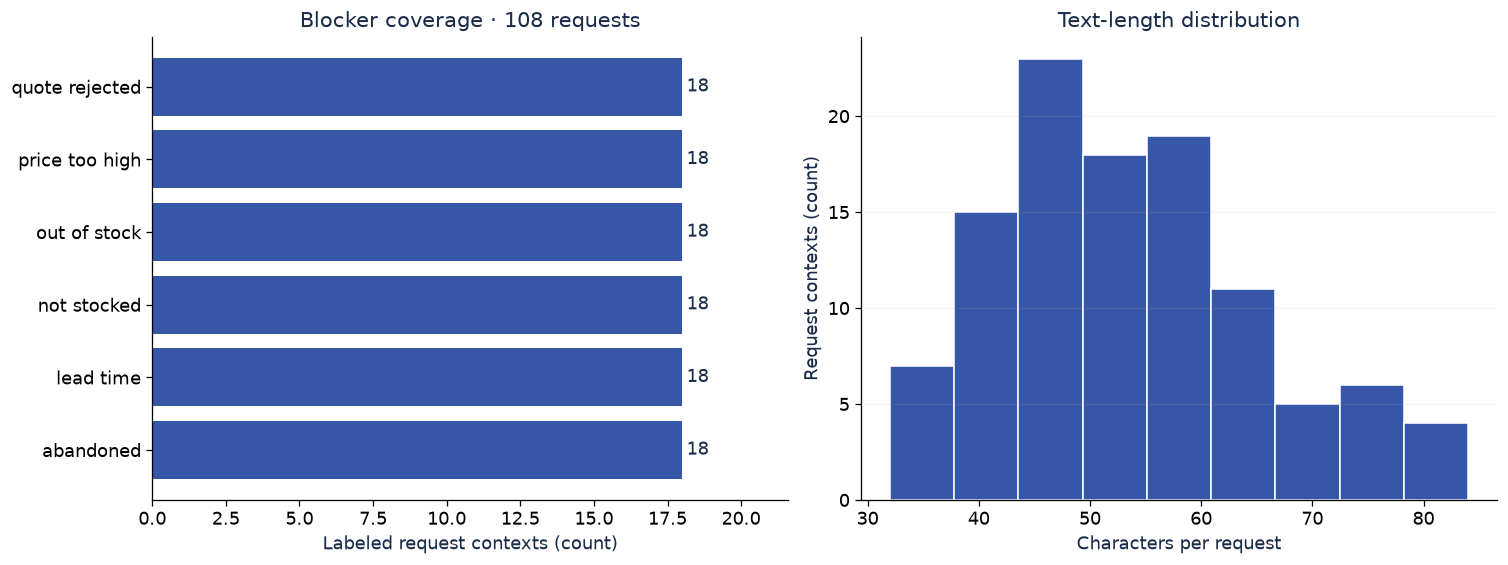

**Interpretation:** Look for absent classes/channels and unusual lengths before fitting. Every row here is synthetic; no real customer accuracy follows from this distribution.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
counts = label_counts.sort_values()
axes[0].barh([name.replace('_',' ') for name in counts.index], counts.values, color=BLUE)
axes[0].set(xlabel='Labeled request contexts (count)', title=f'Blocker coverage · {len(requests_df)} requests')
axes[0].set_xlim(0, max(counts.max()*1.2, 1))
for index, count in enumerate(counts.values):
    axes[0].text(count+.15, index, str(count), va='center')
axes[1].hist(requests_df.characters, bins='auto', color=BLUE, edgecolor='white')
axes[1].set(xlabel='Characters per request', ylabel='Request contexts (count)', title='Text-length distribution')
axes[1].grid(axis='y', alpha=.15)
fig.savefig(OUTPUT_DIR/'eda.png')
plt.show()
display(Markdown('**Interpretation:** Look for absent classes/channels and unusual lengths before fitting. '
    + ('Every row here is synthetic; no real customer accuracy follows from this distribution.'
       if requests_df.is_synthetic.eq('1').all() else 'Report real and synthetic results separately.')))

### 6. Validate and prepare text without destroying retail information

Keep negation, currencies, decimals, size codes and specifications. In the
original cleaning function, removing currency symbols could change the meaning.
The classifier below learns directly from original text with the vectorizer's
standard lowercase behavior, so exported inference matches the app exactly.
`TextPreprocessor` is used only for inspection/clustering; it does not secretly
change the classifier's serving features.

In [7]:
class TextPreprocessor:
    def clean_text(self, text):
        if not isinstance(text, str):
            raise ValueError('Expected text, not a numeric query ID.')
        text = unicodedata.normalize('NFKC', text).casefold()
        text = re.sub(r'https?://\S+|www\.\S+', '[url]', text)
        return ' '.join(text.split())

preprocessor = TextPreprocessor()
assert '$2,500.50' in preprocessor.clean_text('  Budget $2,500.50  ')
assert 'not' in preprocessor.clean_text('NOT in stock')

def validate_requests(frame):
    if frame.id.eq('').any() or frame.id.duplicated().any():
        raise ValueError('Each request needs a nonempty unique id.')
    if frame.text.str.strip().eq('').any() or frame.text.str.len().gt(10000).any():
        raise ValueError('Text needs 1–10,000 characters.')
    if not frame.reason.isin(REASON_LABELS).all():
        raise ValueError('Use the six exact blocker labels; auxiliary public intents are a separate task.')
    if not frame.verified.eq('1').all() or not frame.eligibility.eq('confirmed_unmet').all():
        raise ValueError('Only reviewed labels on confirmed unmet requests enter this training set.')
    if not frame.is_synthetic.isin(['0','1']).all() or frame.origin.eq('').any():
        raise ValueError('Origin and synthetic/real provenance are required.')
    if frame[['group_id','conversation_id']].eq('').any().any():
        raise ValueError('Supply customer/conversation/template grouping before splitting.')
    if frame[['group_id','conversation_id']].apply(lambda column: column.str.contains('REVIEW-ME',regex=False)).any().any():
        raise ValueError('Replace REVIEW-ME placeholders with reviewed conversation/template groups before training.')
    if frame.groupby('normalized_key').reason.nunique().gt(1).any():
        raise ValueError('Resolve conflicting labels for duplicate text before training.')
    if frame.normalized_key.eq('').any():
        raise ValueError('Text has no usable characters.')

validate_requests(requests_df)
requests_df['cleaned_text'] = requests_df.text.map(preprocessor.clean_text)
print('Validation passed. Raw commercial text retained for classifier/extractor.')

Validation passed. Raw commercial text retained for classifier/extractor.


### 7. Group duplicates and conversations before freezing the split

The same conversation/customer/template must not occur in both training and
testing. We link supplied groups and exact normalized duplicates transitively.
This is training-sample deduplication. Actual demand logs must use provider event
IDs and conversation/customer context: two different customers can legitimately
send identical text and should not become one business request.
A conservative lexical similarity screen also links same-label near-duplicates
at cosine ≥0.80. Review candidate IDs; similarity is not proof of a common
template and unknown paraphrases remain a limitation. These inspection features
are discarded before training.

In [8]:
from sklearn.neighbors import NearestNeighbors

frame = requests_df.reset_index(drop=True).copy()
parent = list(range(len(frame)))
def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index
def link(left, right):
    parent[find(left)] = find(right)

seen = {}
for index, row in frame.iterrows():
    for key in [('conversation', row.conversation_id), ('group', row.group_id), ('text', row.normalized_key)]:
        if key in seen:
            link(index, seen[key])
        else:
            seen[key] = index

inspection_features = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5), max_features=6000).fit_transform(frame.text)
neighbors = NearestNeighbors(n_neighbors=min(5, len(frame)), metric='cosine').fit(inspection_features)
distances, neighbor_ids = neighbors.kneighbors(inspection_features)
near_duplicates, paired = [], set()
for left, (ds, js) in enumerate(zip(distances, neighbor_ids)):
    for distance, right in zip(ds, js):
        right = int(right)
        pair = tuple(sorted((left, right)))
        if left == right or pair in paired or distance > .20:
            continue
        paired.add(pair)
        if frame.loc[left,'reason'] == frame.loc[right,'reason']:
            link(left, right)
            near_duplicates.append({'left_id': frame.loc[left,'id'], 'right_id': frame.loc[right,'id'],
                                    'similarity': round(1-float(distance), 3)})
frame['split_group'] = [f'g-{find(i)}' for i in range(len(frame))]
print('Conservative near-duplicate links:', len(near_duplicates))
if near_duplicates:
    display(pd.DataFrame(near_duplicates).head(12))
all_contexts_before_dedup = frame.copy()  # retain later repeated-message dates for time boundaries
frame = frame.drop_duplicates('normalized_key').reset_index(drop=True)
assert frame.reason.nunique() == len(REASON_LABELS)
print('Unique training contexts:', len(frame), '| independent linked groups:', frame.split_group.nunique())

Conservative near-duplicate links: 2


,left_id,right_id,similarity
0,starter-045,starter-092,0.828
1,starter-057,starter-101,0.881


Unique training contexts: 108 | independent linked groups: 106


### 8. Freeze training, validation and test data

Three of five stratified group folds train the model; one selects hyperparameters
and a score threshold; one reports final quality. Vocabulary/IDF are fit on
training only. Group checks catch known duplicates; seed and hashes preserve the
experiment. With real dates, also conduct a later-period grouped evaluation.
Synthetic starter timestamps are unknown, so no time-based accuracy is claimed.
For a real dated dataset, set `SPLIT_STRATEGY='chronological'`. The alternative
branch keeps whole groups, uses earlier/next/later groups, and refuses groups
whose time spans overlap the boundaries. Define explicit cutoffs and purge
spanning conversations before retrying; never hide that overlap.

In [9]:
if SPLIT_STRATEGY == 'grouped':
    folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                 .split(frame.text, frame.reason, groups=frame.split_group))
    partitions = {'train': np.concatenate([folds[i][1] for i in range(3)]),
                  'validation': folds[3][1], 'test': folds[4][1]}
elif SPLIT_STRATEGY == 'chronological':
    dated = all_contexts_before_dedup.copy()
    if dated.captured_at.eq('').any() or not dated.captured_at.map(lambda value: pd.Timestamp(value).tzinfo is not None).all():
        raise ValueError('Chronological evaluation requires a timezone-aware decision time for every row.')
    dated['decision_time'] = pd.to_datetime(dated.captured_at,utc=True)
    bounds = dated.groupby('split_group').decision_time.agg(['min','max']).sort_values('max')
    ordered = bounds.index.tolist()
    a,b = int(len(ordered)*.6),int(len(ordered)*.8)
    group_parts = {'train':ordered[:a],'validation':ordered[a:b],'test':ordered[b:]}
    for left,right in [('train','validation'),('validation','test')]:
        if not group_parts[left] or not group_parts[right] or bounds.loc[group_parts[left],'max'].max() >= bounds.loc[group_parts[right],'min'].min():
            raise ValueError('Group time spans overlap a boundary. Choose cutoffs and purge spanning groups before splitting.')
    partitions = {name:np.flatnonzero(frame.split_group.isin(groups).to_numpy()) for name,groups in group_parts.items()}
else:
    raise ValueError('SPLIT_STRATEGY must be grouped or chronological.')
parts = {name: frame.iloc[indices].copy() for name, indices in partitions.items()}
for name, part in parts.items():
    if set(part.reason) != set(REASON_LABELS):
        raise ValueError(f'{name} misses a reason. Collect more independent groups; do not break grouping to inflate accuracy.')
for left, right in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(parts[left].split_group).isdisjoint(parts[right].split_group)
    assert set(parts[left].normalized_key).isdisjoint(parts[right].normalized_key)

split_manifest = {}
for name, part in parts.items():
    path = OUTPUT_DIR/f'{name}.csv'
    part.to_csv(path, index=False)
    split_manifest[name] = {'rows': len(part), 'sha256': sha256_file(path),
                            'classes': {key: int(value) for key,value in part.reason.value_counts().items()}}
save_json(OUTPUT_DIR/'split_manifest.json', split_manifest)
display(pd.crosstab(frame.reason, pd.Series({int(i): name for name, ids in partitions.items() for i in ids})))
print({name: len(part) for name,part in parts.items()})

col_0,test,train,validation
reason,,,
abandoned,4,10,4
lead_time,4,11,3
not_stocked,3,11,4
out_of_stock,4,10,4
price_too_high,3,12,3
quote_rejected,3,12,3


{'train': 66, 'validation': 21, 'test': 21}


### 9. Train the blocker classifier and select settings on validation

TF-IDF gives each character fragment a weight based on its rarity in training.
Logistic regression learns how those fragments predict the six labels. It learns
from reviewed text, not from the dashboard's own unverified predictions.

We compare three regularization strengths (`C`), use balanced class weights and
choose the best validation macro F1. This preserves your original class-based
structure while replacing its unrelated intent names with the app's reasons.

In [10]:
class IntentClassifier:
    'Six-way blocker classifier; call only after confirming an unmet request.'
    def __init__(self):
        self.vectorizer = TfidfVectorizer(**VECTORIZER_PARAMS)
        self.classifier = None
        self.threshold = 1.0
        self.version = 'unsaved'

    def train(self, training, validation):
        x_train = self.vectorizer.fit_transform(training.text)
        x_validation = self.vectorizer.transform(validation.text)
        candidates, best = [], None
        for c in [.5, 2., 8.]:
            candidate = LogisticRegression(C=c, class_weight='balanced', max_iter=1000, random_state=SEED)
            candidate.fit(x_train, training.reason)
            predicted = candidate.predict(x_validation)
            predicted = predicted.astype(object)
            predicted[x_validation.getnnz(axis=1) == 0] = '__no_prediction__'
            score = f1_score(validation.reason, predicted, labels=REASON_LABELS, average='macro', zero_division=0)
            candidates.append({'C': c, 'validation_macro_f1': float(score)})
            if best is None or score > best[0]:
                best = float(score), c, candidate
        self.validation_f1, self.selected_c, self.classifier = best
        self.classes = self.classifier.classes_.tolist()
        return pd.DataFrame(candidates)

    def predict(self, text):
        if self.classifier is None:
            raise RuntimeError('Train the classifier before prediction; no fabricated default confidence.')
        features = self.vectorizer.transform([text])
        if features.nnz == 0:
            return None
        scores = self.classifier.predict_proba(features)[0]
        index = int(scores.argmax())
        return {'reason': self.classes[index], 'confidence': round(float(scores[index]),4),
                'used': bool(scores[index] >= self.threshold), 'model_version': self.version}

reason_model = IntentClassifier()
candidate_scores = reason_model.train(parts['train'], parts['validation'])
display(candidate_scores.round(4))
print('Selected C:', reason_model.selected_c)

,C,validation_macro_f1
0,0.5,0.8128
1,2.0,0.8128
2,8.0,0.8128


Selected C: 0.5


### 10. Set an abstention threshold using validation, not test

The largest class score is **uncalibrated**, not a promise of correctness.
Choose the most validation coverage meeting the stated selective-accuracy target
and minimum sample count. If none qualifies, use threshold 1.0 and defer all
current examples. Do not lower the target to make a demonstration appear certain.
No-feature messages always defer.

,threshold,accepted,coverage,accepted_accuracy
0,0.25,2,0.095,1.0
1,0.35,0,0.000,NaN
2,0.45,0,0.000,NaN
3,0.55,0,0.000,NaN
4,0.65,0,0.000,NaN
5,0.75,0,0.000,NaN
6,0.85,0,0.000,NaN
7,0.95,0,0.000,NaN


Selected threshold: 1.0
No tested threshold met the validation policy. Keep all predictions under human review.


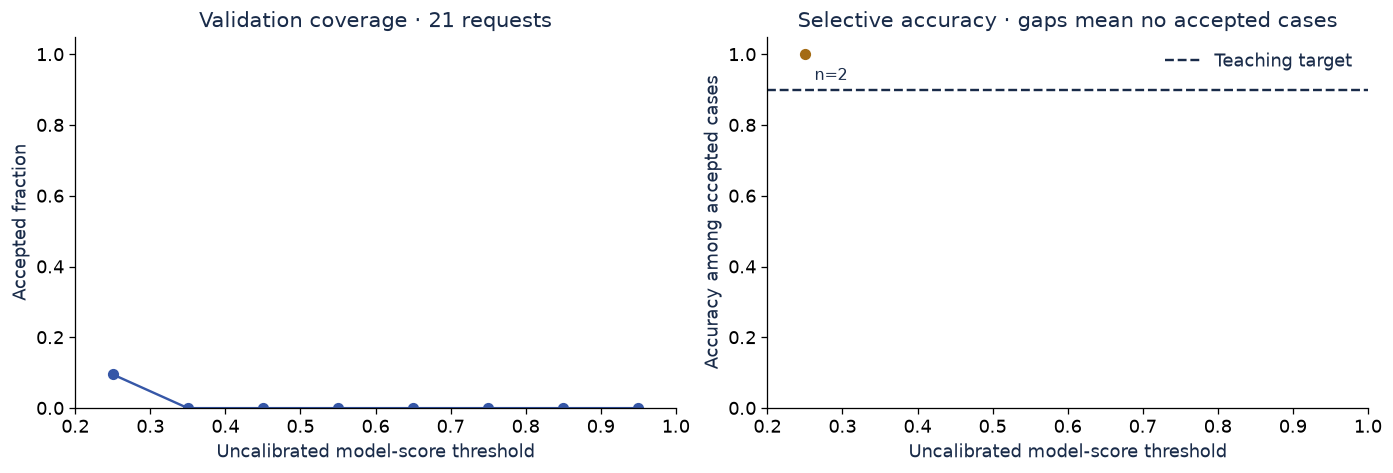

In [11]:
x_validation = reason_model.vectorizer.transform(parts['validation'].text)
validation_probabilities = reason_model.classifier.predict_proba(x_validation)
validation_predictions = np.asarray(reason_model.classes)[validation_probabilities.argmax(axis=1)]
validation_known = x_validation.getnnz(axis=1) > 0
threshold_rows = []
for threshold in [.25,.35,.45,.55,.65,.75,.85,.95]:
    used = (validation_probabilities.max(axis=1) >= threshold) & validation_known
    threshold_rows.append({'threshold': threshold, 'accepted': int(used.sum()), 'coverage': float(used.mean()),
        'accepted_accuracy': float(np.mean(validation_predictions[used] == parts['validation'].reason.to_numpy()[used])) if used.any() else np.nan})
threshold_table = pd.DataFrame(threshold_rows)
eligible = threshold_table[(threshold_table.accepted >= MIN_ACCEPTED_VALIDATION) &
                           (threshold_table.accepted_accuracy >= TARGET_ACCEPTED_ACCURACY)]
reason_model.threshold = float(eligible.sort_values(['coverage','threshold'], ascending=[False,True]).iloc[0].threshold) if len(eligible) else 1.0
display(threshold_table.round(3))
print('Selected threshold:', reason_model.threshold)
if reason_model.threshold == 1.0:
    print('No tested threshold met the validation policy. Keep all predictions under human review.')

fig, axes = plt.subplots(1, 2, figsize=(12,4), layout='constrained')
axes[0].plot(threshold_table.threshold, threshold_table.coverage, marker='o', color=BLUE)
axes[0].set(xlabel='Uncalibrated model-score threshold', ylabel='Accepted fraction', ylim=(0,1.05),
            xlim=(.2,1.0),title=f'Validation coverage · {len(parts["validation"])} requests')
axes[1].plot(threshold_table.threshold, threshold_table.accepted_accuracy, marker='o', color=GOLD)
axes[1].axhline(TARGET_ACCEPTED_ACCURACY, color=INK, linestyle='--', label='Teaching target')
axes[1].set(xlabel='Uncalibrated model-score threshold', ylabel='Accuracy among accepted cases', ylim=(0,1.05),
            xlim=(.2,1.0),title='Selective accuracy · gaps mean no accepted cases')
for point in threshold_table.dropna(subset=['accepted_accuracy']).itertuples():
    axes[1].annotate(f'n={point.accepted}',xy=(point.threshold,point.accepted_accuracy),
                     xytext=(6,-16),textcoords='offset points',fontsize=10)
axes[1].legend(frameon=False)
fig.savefig(OUTPUT_DIR/'validation_thresholds.png')
plt.show()

### 11. Evaluate the frozen candidate on test data and inspect errors

Macro F1 weights each blocker equally. Accuracy alone can hide a weak class.
Always show sample counts and coverage alongside accuracy among accepted cases.
The dummy baseline predicts the most frequent training label. Missing-vocabulary
predictions count as errors/deferred cases rather than a class-prior guess.

In [12]:
def evaluate_reason_model(model, test_frame):
    features = model.vectorizer.transform(test_frame.text)
    probabilities = model.classifier.predict_proba(features)
    known = features.getnnz(axis=1) > 0
    predictions = np.asarray(model.classes, dtype=object)[probabilities.argmax(axis=1)]
    predictions[~known] = '__no_prediction__'
    accepted = (probabilities.max(axis=1) >= model.threshold) & known
    truth = test_frame.reason.to_numpy()
    return {'examples': len(test_frame), 'accuracy': float(accuracy_score(truth,predictions)),
        'macro_f1': float(f1_score(truth,predictions,labels=REASON_LABELS,average='macro',zero_division=0)),
        'prediction_missing': int((~known).sum()), 'coverage': float(accepted.mean()), 'accepted': int(accepted.sum()),
        'accepted_accuracy': float(np.mean(predictions[accepted]==truth[accepted])) if accepted.any() else None,
        'threshold': model.threshold}, probabilities, predictions, accepted

test_metrics, test_probabilities, test_predictions, test_accepted = evaluate_reason_model(reason_model, parts['test'])
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(parts['train']),1)),parts['train'].reason)
dummy_predictions = dummy.predict(np.zeros((len(parts['test']),1)))
comparison = pd.DataFrame([
    {'Model':'Most-frequent-label baseline','Test macro F1': f1_score(parts['test'].reason,dummy_predictions,labels=REASON_LABELS,average='macro',zero_division=0)},
    {'Model':'Character TF-IDF + logistic regression','Test macro F1': test_metrics['macro_f1']},
])
display(comparison.round(3))
display(pd.Series(test_metrics, name='Observed test value').to_frame())
per_class = pd.DataFrame(classification_report(parts['test'].reason, test_predictions, labels=REASON_LABELS,
                                             output_dict=True,zero_division=0)).T
display(per_class.loc[list(REASON_LABELS)].round(3))
error_table = parts['test'][['id','reason','source','is_synthetic']].copy()
error_table['predicted'] = test_predictions
error_table['score'] = test_probabilities.max(axis=1)
error_table['accepted'] = test_accepted
error_table.to_csv(OUTPUT_DIR/'test_predictions.csv',index=False)
display(error_table[error_table.reason != error_table.predicted].head(8).round(3))
slice_results = []
for (source,is_synthetic),indices in parts['test'].reset_index(drop=True).groupby(['source','is_synthetic']).groups.items():
    indices = np.asarray(list(indices),dtype=int)
    slice_results.append({'Source':source,'Synthetic':is_synthetic,'Requests':len(indices),
        'Accuracy':float(np.mean(test_predictions[indices] == parts['test'].reason.to_numpy()[indices]))})
display(pd.DataFrame(slice_results).round(3))

,Model,Test macro F1
0,Most-frequent-label baseline,0.042
1,Character TF-IDF + logistic regression,0.860


,Observed test value
examples,21.000000
accuracy,0.857143
macro_f1,0.860450
prediction_missing,0.000000
coverage,0.000000
accepted,0.000000
accepted_accuracy,NaN
threshold,1.000000


,precision,recall,f1-score,support
abandoned,0.8,1.00,0.889,4.0
lead_time,1.0,0.75,0.857,4.0
not_stocked,0.6,1.00,0.750,3.0
out_of_stock,1.0,0.50,0.667,4.0
price_too_high,1.0,1.00,1.000,3.0
quote_rejected,1.0,1.00,1.000,3.0


,id,reason,source,is_synthetic,predicted,score,accepted
2,starter-002,out_of_stock,synthetic,1,not_stocked,0.194,False
77,starter-077,out_of_stock,synthetic,1,not_stocked,0.185,False
96,starter-096,lead_time,synthetic,1,abandoned,0.210,False


,Source,Synthetic,Requests,Accuracy
0,synthetic,1,21,0.857


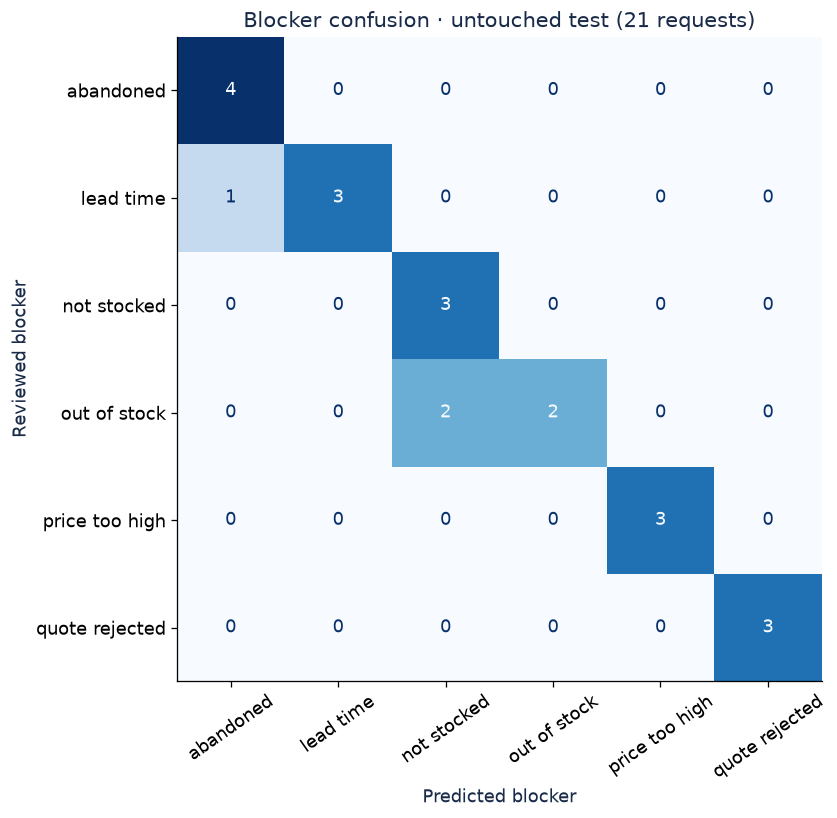

**Error review:** Join IDs to the local test CSV, inspect ambiguous context, label disagreements and channel/language gaps. Improve training data using validation; do not repeatedly tune on this test set. These scores describe this small input population only.

In [13]:
matrix_labels = list(REASON_LABELS) + (['__no_prediction__'] if '__no_prediction__' in test_predictions else [])
matrix = confusion_matrix(parts['test'].reason,test_predictions,labels=matrix_labels)
fig, ax = plt.subplots(figsize=(10,7),layout='constrained')
ConfusionMatrixDisplay(matrix,display_labels=[name.replace('_',' ') for name in matrix_labels]).plot(
    ax=ax,cmap='Blues',colorbar=False,values_format='d',xticks_rotation=35)
ax.set(title=f'Blocker confusion · untouched test ({len(parts["test"])} requests)',
       xlabel='Predicted blocker',ylabel='Reviewed blocker')
fig.savefig(OUTPUT_DIR/'test_confusion.png')
plt.show()
display(Markdown('**Error review:** Join IDs to the local test CSV, inspect ambiguous context, '
    'label disagreements and channel/language gaps. Improve training data using validation; '
    'do not repeatedly tune on this test set. These scores describe this small input population only.'))

### 12. Optional supervised upgrade: SetFit + MiniLM

This cell actually fine-tunes a sentence encoder and classifier head when
`RUN_SETFIT=True`. It uses the same frozen partitions. One epoch/small batches
are a starting experiment, not an established optimum. Compare validation
macro F1 before deciding on a candidate; keep the test for final reporting.

[SetFit training and saving](https://huggingface.co/docs/setfit/en/quickstart)
differs from simply loading an encoder. An English checkpoint does not establish
Swahili/mixed-language performance. Loading weights may require network access
and more memory. The default run skips this step explicitly.

In [14]:
setfit_model = None
setfit_result = None
if RUN_SETFIT:
    optional = ['setfit>=1.1,<2','sentence-transformers[train]>=3.4,<6','transformers>=4.48,<5','datasets>=3,<5']
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*optional])
    from datasets import Dataset
    from setfit import SetFitModel, Trainer, TrainingArguments
    from transformers import set_seed
    set_seed(SEED)
    labels = list(REASON_LABELS)
    dataset = Dataset.from_dict({'text':parts['train'].text.tolist(),
                                  'label':[labels.index(label) for label in parts['train'].reason]})
    setfit_model = SetFitModel.from_pretrained('sentence-transformers/all-MiniLM-L6-v2',labels=labels)
    arguments = TrainingArguments(output_dir=str(OUTPUT_DIR/'setfit_checkpoints'),batch_size=8,
                                   num_epochs=1,num_iterations=10,seed=SEED,report_to='none')
    Trainer(model=setfit_model,args=arguments,train_dataset=dataset).train()
    validation_guess = np.asarray(setfit_model.predict(parts['validation'].text.tolist()))
    # labels=... makes predict return readable blocker names.
    setfit_validation_f1 = f1_score(parts['validation'].reason,validation_guess,labels=labels,average='macro',zero_division=0)
    setfit_model.save_pretrained(str(OUTPUT_DIR/'setfit_model'))
    setfit_result = {'validation_macro_f1':float(setfit_validation_f1), 'training_examples':len(parts['train']),
                     'base_model':'sentence-transformers/all-MiniLM-L6-v2','epochs':1}
    save_json(OUTPUT_DIR/'setfit_experiment.json',setfit_result)
    print('SetFit validation macro F1:',round(setfit_validation_f1,3),
          '| baseline:',round(reason_model.validation_f1,3))
    print('Saved candidate, not promoted. Test evaluation, threshold validation and a separate SetFit adapter are required before rollout.')
else:
    print('SKIPPED: SetFit training. Enable RUN_SETFIT to run this supervised experiment.')

SKIPPED: SetFit training. Enable RUN_SETFIT to run this supervised experiment.


### 13. Extract retail fields conservatively from the original text

This is a **rule baseline**, not a trained NER model. We require clear quantity
units, keep currency separate from amount, preserve decimals/thousands and
separate product specifications from quantity. A bare `$` is ambiguous without
currency context. Conflicting monetary mentions defer for review.
An amount is kept as `amount_mentioned`; it becomes a budget only when explicit
budget language is present. Listed prices and customer budgets are different.

To train NER later, annotate PRODUCT/QUANTITY/BUDGET/CURRENCY/LOCATION spans and
evaluate span F1 plus exact parsed-field agreement. General NER labels do not
supply those annotations. Do not call an imported `spacy` package a trained model.

In [15]:
@dataclass
class ExtractedEntities:
    quantity: Optional[int] = None
    amount_mentioned: Optional[float] = None
    budget: Optional[float] = None
    currency: str = 'UNKNOWN'
    specifications: list = field(default_factory=list)
    warnings: list = field(default_factory=list)

class EntityExtractor:
    MONEY_NUMBER = r'(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?(?:k)?'
    CURRENCY = r'(?:KES|KSHS?|USD|EUR|GBP|\$|€|£)'

    def extract(self, text):
        result = ExtractedEntities()
        quantity = re.search(r'\b(\d+)\s*(?:pcs|pieces|units|bags|pairs|cartons|items)\b|\b(?:qty|quantity)\s*[:=]?\s*(\d+)\b', text, re.I)
        if quantity:
            quantity_value = int(quantity.group(1) or quantity.group(2))
            if quantity_value > 0:
                result.quantity = quantity_value
        currency_names = {'kes':'KES','ksh':'KES','kshs':'KES','usd':'USD','eur':'EUR','gbp':'GBP','€':'EUR','£':'GBP','$':'UNKNOWN'}
        money_pattern = rf'(?P<currency1>{self.CURRENCY})\s*(?P<amount1>{self.MONEY_NUMBER})(?!(?:\w|,\d|\.\d))|(?<![\w,.\-])(?P<amount2>{self.MONEY_NUMBER})\s*(?P<currency2>{self.CURRENCY})(?!\w)'
        mentions = []
        for match in re.finditer(money_pattern, text, re.I):
            currency = currency_names[(match.group('currency1') or match.group('currency2')).lower()]
            amount = (match.group('amount1') or match.group('amount2')).replace(',','').lower()
            value = float(amount[:-1])*1000 if amount.endswith('k') else float(amount)
            if math.isfinite(value):
                mentions.append((value,currency))
        unique = set(mentions)
        if len(unique) == 1:
            result.amount_mentioned, result.currency = next(iter(unique))
            if re.search(r'\bbudget\b|\bafford\b|\bspend\b|\bunder\b|\bmaximum\b|\bup to\b',text,re.I):
                result.budget = result.amount_mentioned
            if result.currency == 'UNKNOWN':
                result.warnings.append('Dollar currency is ambiguous; confirm the currency.')
        elif len(unique) > 1:
            result.warnings.append('Multiple prices/currencies mentioned; do not guess the customer budget.')
        if not mentions and re.search(self.CURRENCY,text,re.I):
            result.warnings.append('Currency/amount format needs review; do not guess decimal separators or negative values.')
        result.specifications = [match.group().strip() for match in re.finditer(
            r'\b\d[\d,]*(?:\.\d+)?\s*(?:mAh|Ah|kV|kW|V|W|HP|inch|GB|TB|mm|kg)\b|\bsize\s+[A-Z0-9]+\b', text, re.I)]
        return result

extractor = EntityExtractor()
entity_checks = [
    ('Need 2 units of 20000mAh power bank, budget KES 2,500.50', 2,2500.5,'KES'),
    ('The 20000mAh power bank is sold out', None,None,'UNKNOWN'),
    ('Need shoes size 42, budget KES 5000', None,5000.,'KES'),
    ('Quantity=3 bags, budget 2.5k KES', 3,2500.,'KES'),
    ('USB-C charger 30W, price USD 19.99', None,None,'USD'),
    ('Budget $500', None,500.,'UNKNOWN'),
    ('Quote KES 5000; customer budget KES 4000', None,None,'UNKNOWN'),
    ('Budget EUR2,50', None,None,'UNKNOWN'),
    ('Budget -100 KES', None,None,'UNKNOWN'),
]
for text, quantity, budget, currency in entity_checks:
    observed = extractor.extract(text)
    assert (observed.quantity, observed.budget, observed.currency) == (quantity,budget,currency), (text,observed)
display(pd.DataFrame([{'Example':text,**asdict(extractor.extract(text))} for text,*_ in entity_checks]))
print('All quantity/amount/currency regression examples passed. They are examples, not an NER benchmark.')
assert extractor.extract('Charger price USD 19.99').amount_mentioned == 19.99
assert extractor.extract('Charger price USD 19.99').budget is None

,Example,quantity,amount_mentioned,budget,currency,specifications,warnings
0,"Need 2 units of 20000mAh power bank, budget KE...",2.0,2500.50,2500.5,KES,[20000mAh],[]
1,The 20000mAh power bank is sold out,NaN,NaN,NaN,UNKNOWN,[20000mAh],[]
2,"Need shoes size 42, budget KES 5000",NaN,5000.00,5000.0,KES,[size 42],[]
3,"Quantity=3 bags, budget 2.5k KES",3.0,2500.00,2500.0,KES,[],[]
4,"USB-C charger 30W, price USD 19.99",NaN,19.99,NaN,USD,[30W],[]
5,Budget $500,NaN,500.00,500.0,UNKNOWN,[],[Dollar currency is ambiguous; confirm the cur...
6,Quote KES 5000; customer budget KES 4000,NaN,NaN,NaN,UNKNOWN,[],[Multiple prices/currencies mentioned; do not ...
7,"Budget EUR2,50",NaN,NaN,NaN,UNKNOWN,[],[Currency/amount format needs review; do not g...
8,Budget -100 KES,NaN,NaN,NaN,UNKNOWN,[],[Currency/amount format needs review; do not g...


All quantity/amount/currency regression examples passed. They are examples, not an NER benchmark.


### 14. Product matching is a separate retrieval problem

The included eight fictional SKUs and 24 queries make this notebook portable.
Validation queries choose a lexical representation; separate test queries report
Recall@1/3 and mean reciprocal rank (MRR). The same catalog is available at
deployment, so indexing catalog text is allowed; test-query judgments are not
training features. Single-letter sizes (`M`, `L`) must survive tokenization.

This retrieves **candidates**. It does not prove stock, affordability, the exact
variant or a failed sale. Requests with no matching product need their own
rejection evaluation. These easy synthetic queries do not measure general search
quality. For an ESCI experiment use examples/products parquet with E/S/C/I
judgments and query-group splits; source IDs alone cannot train matching.

In [16]:
CATALOG_EXAMPLES = [
    {"product_id": "P01", "title": "Wireless noise cancelling headphones", "description": "Over ear Bluetooth headphones black", "origin": "synthetic_teaching_example"},
    {"product_id": "P02", "title": "Wired USB-C earphones", "description": "In ear headset USB Type C white", "origin": "synthetic_teaching_example"},
    {"product_id": "P03", "title": "USB-C power bank 10000mAh", "description": "Portable charger 20W black", "origin": "synthetic_teaching_example"},
    {"product_id": "P04", "title": "USB-C power bank 20000mAh", "description": "Portable charger 30W black", "origin": "synthetic_teaching_example"},
    {"product_id": "P05", "title": "Cotton T-shirt navy size M", "description": "Short sleeve cotton top medium", "origin": "synthetic_teaching_example"},
    {"product_id": "P06", "title": "Cotton T-shirt navy size L", "description": "Short sleeve cotton top large", "origin": "synthetic_teaching_example"},
    {"product_id": "P07", "title": "Running shoes size 42", "description": "Lightweight trainers adult EU42 black", "origin": "synthetic_teaching_example"},
    {"product_id": "P08", "title": "Running shoes size 43", "description": "Lightweight trainers adult EU43 black", "origin": "synthetic_teaching_example"}
]

QUERY_EXAMPLES = [
    {"query_id": "Q01", "query": "Bluetooth headphones with noise cancelling", "relevant_ids": "P01", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q02", "query": "USB Type C wired headset", "relevant_ids": "P02", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q03", "query": "10000mAh portable charger", "relevant_ids": "P03", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q04", "query": "20000mAh portable charger", "relevant_ids": "P04", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q05", "query": "medium navy cotton shirt", "relevant_ids": "P05", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q06", "query": "large navy cotton shirt", "relevant_ids": "P06", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q07", "query": "black trainers EU42", "relevant_ids": "P07", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q08", "query": "black trainers EU43", "relevant_ids": "P08", "split": "train", "origin": "synthetic_teaching_example"},
    {"query_id": "Q09", "query": "over ear wireless headphones", "relevant_ids": "P01", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q10", "query": "white USB-C earphones", "relevant_ids": "P02", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q11", "query": "power bank 10000mAh 20W", "relevant_ids": "P03", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q12", "query": "power bank 20000mAh 30W", "relevant_ids": "P04", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q13", "query": "navy T-shirt size M", "relevant_ids": "P05", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q14", "query": "navy T-shirt size L", "relevant_ids": "P06", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q15", "query": "running shoes size 42", "relevant_ids": "P07", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q16", "query": "running shoes size 43", "relevant_ids": "P08", "split": "validation", "origin": "synthetic_teaching_example"},
    {"query_id": "Q17", "query": "noise cancelling Bluetooth headset black", "relevant_ids": "P01", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q18", "query": "wired in ear USB-C headset white", "relevant_ids": "P02", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q19", "query": "portable power bank 10000mAh", "relevant_ids": "P03", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q20", "query": "portable power bank 20000mAh", "relevant_ids": "P04", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q21", "query": "short sleeve navy cotton top medium", "relevant_ids": "P05", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q22", "query": "short sleeve navy cotton top large", "relevant_ids": "P06", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q23", "query": "lightweight black running trainers size 42", "relevant_ids": "P07", "split": "test", "origin": "synthetic_teaching_example"},
    {"query_id": "Q24", "query": "lightweight black running trainers size 43", "relevant_ids": "P08", "split": "test", "origin": "synthetic_teaching_example"}
]


catalog = pd.DataFrame(CATALOG_EXAMPLES)
queries = pd.DataFrame(QUERY_EXAMPLES)
catalog['document'] = catalog.title + '. ' + catalog.description
assert catalog.product_id.is_unique and queries.query_id.is_unique
assert set(queries.split) == {'train','validation','test'}
assert queries.groupby(queries['query'].map(normalized_key)).split.nunique().max() == 1
display(catalog[['product_id','title']])

,product_id,title
0,P01,Wireless noise cancelling headphones
1,P02,Wired USB-C earphones
2,P03,USB-C power bank 10000mAh
3,P04,USB-C power bank 20000mAh
4,P05,Cotton T-shirt navy size M
5,P06,Cotton T-shirt navy size L
6,P07,Running shoes size 42
7,P08,Running shoes size 43


In [17]:
class CatalogMatcher:
    def __init__(self, catalog_frame):
        self.catalog = catalog_frame.copy()
        self.vectorizer = None
        self.matrix = None
        self.encoder = None

    def fit(self, validation_queries):
        best, comparisons = None, []
        settings = [dict(analyzer='word',ngram_range=(1,2),token_pattern=r'(?u)\b\w+\b'),
                    dict(analyzer='char_wb',ngram_range=(3,5))]
        for setting in settings:
            self.vectorizer = TfidfVectorizer(sublinear_tf=True,**setting)
            self.matrix = self.vectorizer.fit_transform(self.catalog.document)
            metrics = self.evaluate(validation_queries)
            comparisons.append({'Representation':setting['analyzer'],'Validation Recall@1':metrics['recall_at_1']})
            if best is None or metrics['recall_at_1'] > best[0]:
                best = metrics['recall_at_1'], self.vectorizer, self.matrix
        _,self.vectorizer,self.matrix = best
        return pd.DataFrame(comparisons)

    def scores(self, text):
        if self.encoder is not None:
            return self.encoder.encode([text],normalize_embeddings=True,show_progress_bar=False)[0] @ self.matrix.T
        return (self.vectorizer.transform([text]) @ self.matrix.T).toarray().ravel()

    def search(self, text, k=3):
        scores = np.asarray(self.scores(text))
        if not np.any(scores > 0):
            return []
        ranks = np.argsort(-scores,kind='stable')[:k]
        return [{'product_id':self.catalog.iloc[int(i)].product_id,'title':self.catalog.iloc[int(i)].title,
                 'similarity':round(float(scores[i]),5),'requires_review':True} for i in ranks]

    def evaluate(self, query_frame):
        recall1,recall3,reciprocal = [],[],[]
        for row in query_frame.itertuples():
            ranked = [item['product_id'] for item in self.search(row.query,len(self.catalog))]
            relevant = set(row.relevant_ids.split('|'))
            recall1.append(len(set(ranked[:1]) & relevant)/len(relevant))
            recall3.append(len(set(ranked[:3]) & relevant)/len(relevant))
            reciprocal.append(next((1/(i+1) for i,item in enumerate(ranked) if item in relevant),0))
        return {'queries':len(query_frame),'recall_at_1':float(np.mean(recall1)),
                'recall_at_3':float(np.mean(recall3)),'mrr':float(np.mean(reciprocal))}

matcher = CatalogMatcher(catalog)
display(matcher.fit(queries[queries.split=='validation']).round(3))
matching_metrics = matcher.evaluate(queries[queries.split=='test'])
display(pd.Series(matching_metrics,name='Synthetic test result').to_frame())
display(pd.DataFrame(matcher.search('navy cotton T-shirt size L')))
assert matcher.search('navy cotton T-shirt size L')[0]['product_id'] == 'P06'
assert matcher.search('USB-C power bank 20000mAh')[0]['product_id'] == 'P04'

,Representation,Validation Recall@1
0,word,1.000
1,char_wb,0.875


,Synthetic test result
queries,8.0
recall_at_1,1.0
recall_at_3,1.0
mrr,1.0


,product_id,title,similarity,requires_review
0,P06,Cotton T-shirt navy size L,0.67888,True
1,P05,Cotton T-shirt navy size M,0.48773,True
2,P07,Running shoes size 42,0.04329,True


### 15. Optional pretrained MiniLM matching and demand clustering

When enabled, MiniLM generates normalized embeddings for cosine retrieval. This
**does not fine-tune the encoder**. Compare its validation retrieval score and
wrong-size/model errors against the lexical baseline. This notebook keeps the
baseline unless the validation comparison supports changing it.

HDBSCAN is unsupervised batch clustering, not a six-way classifier. With the
default lexical features, call clusters lexical; with pretrained MiniLM features,
call them embedding clusters. IDs are local to a fit, and `-1` is noise, not one
large business opportunity. Manual cluster coherence and actual SKU checks are
needed before converting clusters into stock recommendations.
Clustering describes the practice batch; its features never enter the classifier
or its hyperparameter selection.

SKIPPED: pretrained MiniLM download. Lexical retrieval remains available.


/tmp/ghostdemand-notebook-env/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,Distinct request contexts
cluster_id,
-1,18
0,4
1,5
2,5
3,4
4,13
5,4
6,6
7,5


Clustering backend: lexical TF-IDF/SVD | noise fraction: 0.167
Descriptive silhouette on non-noise cases: 0.143


,distinct_request_contexts
cluster_id,
0,4
1,5
2,5
3,4
4,13
5,4
6,6
7,5
8,4


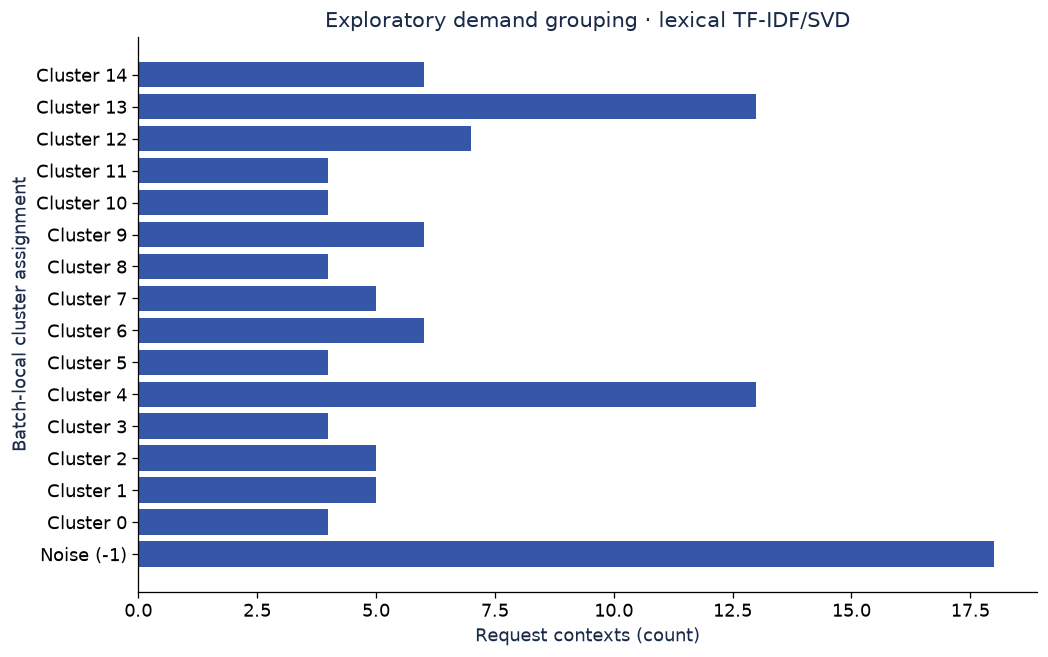

In [18]:
semantic_encoder = None
semantic_metrics = None
if RUN_SEMANTIC:
    if importlib.util.find_spec('sentence_transformers') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','--quiet','sentence-transformers>=3.4,<6'])
    from sentence_transformers import SentenceTransformer
    semantic_encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',trust_remote_code=False)
    semantic_matcher = CatalogMatcher(catalog)
    semantic_matcher.encoder = semantic_encoder
    semantic_matcher.matrix = semantic_encoder.encode(catalog.document.tolist(),normalize_embeddings=True,show_progress_bar=False)
    semantic_validation = semantic_matcher.evaluate(queries[queries.split=='validation'])
    lexical_validation = matcher.evaluate(queries[queries.split=='validation'])
    display(pd.DataFrame([{'Backend':'Lexical',**lexical_validation},{'Backend':'Pretrained MiniLM',**semantic_validation}]))
    semantic_metrics = semantic_matcher.evaluate(queries[queries.split=='test'])
    print('Pretrained MiniLM test:',semantic_metrics,'; no automatic backend change.')
else:
    print('SKIPPED: pretrained MiniLM download. Lexical retrieval remains available.')

class DemandClusterer:
    def __init__(self, encoder=None, min_cluster_size=4):
        self.encoder = encoder
        self.min_cluster_size = min_cluster_size
        self.backend = 'pretrained MiniLM embeddings' if encoder is not None else 'lexical TF-IDF/SVD'

    def fit_predict(self,texts):
        if len(texts) < max(5,self.min_cluster_size):
            self.embeddings = None
            return [-1]*len(texts)
        if self.encoder is not None:
            embeddings = self.encoder.encode(texts,normalize_embeddings=True,show_progress_bar=False)
        else:
            matrix = TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=6000).fit_transform(texts)
            components = min(30,matrix.shape[0]-1,matrix.shape[1]-1)
            if components < 2:
                self.embeddings = None
                return [-1]*len(texts)
            embeddings = normalize(TruncatedSVD(n_components=components,random_state=SEED).fit_transform(matrix))
        self.embeddings = embeddings
        return HDBSCAN(min_cluster_size=self.min_cluster_size,min_samples=2,metric='euclidean').fit_predict(embeddings).tolist()

clusterer = DemandClusterer(semantic_encoder)
assert DemandClusterer().fit_predict([]) == []
assert DemandClusterer().fit_predict(['single request']) == [-1]
cluster_sample = frame[['id','text']].head(500).copy()
cluster_sample['cleaned_text'] = cluster_sample.text.map(preprocessor.clean_text)
cluster_sample['cluster_id'] = clusterer.fit_predict(cluster_sample.cleaned_text.tolist())
cluster_counts = cluster_sample.cluster_id.value_counts().sort_index()
display(cluster_counts.rename('Distinct request contexts').to_frame())
cluster_noise = float(cluster_sample.cluster_id.eq(-1).mean())
print('Clustering backend:',clusterer.backend,'| noise fraction:',round(cluster_noise,3))
non_noise = cluster_sample.cluster_id.ne(-1).to_numpy()
labels = cluster_sample.loc[non_noise,'cluster_id'].to_numpy()
if clusterer.embeddings is not None and 1 < len(set(labels)) < len(labels):
    print('Descriptive silhouette on non-noise cases:',round(silhouette_score(clusterer.embeddings[non_noise],labels),3))
else:
    print('Silhouette undefined: need at least two non-noise clusters and more points than clusters.')
cluster_opportunities = (cluster_sample[cluster_sample.cluster_id.ge(0)]
    .groupby('cluster_id').agg(distinct_request_contexts=('id','nunique')))
display(cluster_opportunities)
assert -1 not in cluster_opportunities.index

fig, ax = plt.subplots(figsize=(9,max(4,len(cluster_counts)*.35)),layout='constrained')
ax.barh([('Noise (-1)' if i == -1 else f'Cluster {i}') for i in cluster_counts.index],cluster_counts.values,color=BLUE)
ax.set(ylabel='Batch-local cluster assignment',xlabel='Request contexts (count)',
       title=f'Exploratory demand grouping · {clusterer.backend}')
fig.savefig(OUTPUT_DIR/'cluster_counts.png')
plt.show()

### 16. Assemble the integration pipeline with an eligibility gate

Channel capture/transcription comes before this pipeline. Only confirmed unmet
requests receive a blocker suggestion. Everyone else gets an explicit review
state. The extractor and matcher retain their own limitations; candidates do not
silently overwrite a SKU. High scores are still unverified until reviewed.

In [19]:
@dataclass
class RawInteraction:
    channel: str
    raw_text: str
    eligibility: str = 'pending'
    timestamp: Optional[str] = None
    interaction_id: Optional[str] = None

    def __post_init__(self):
        if not isinstance(self.raw_text,str) or not 1 <= len(self.raw_text.strip()) <= 10000:
            raise ValueError('Raw text needs 1–10,000 characters.')
        if self.eligibility not in {'pending','confirmed_unmet','fulfilled','not_a_request'}:
            raise ValueError('Unsupported eligibility state.')
        # Prefer the provider's event ID. A fresh fallback avoids merging two
        # different customers merely because they sent identical text.
        self.interaction_id = self.interaction_id or uuid4().hex

class GhostDemandEngine:
    def __init__(self, classifier, entity_extractor, catalog_matcher):
        self.classifier,self.entity_extractor,self.catalog_matcher = classifier,entity_extractor,catalog_matcher

    def process(self,interaction):
        reason = self.classifier.predict(interaction.raw_text) if interaction.eligibility == 'confirmed_unmet' else None
        return {'interaction_id':interaction.interaction_id,'source':interaction.channel,
                'eligibility':interaction.eligibility,'captured_at':interaction.timestamp,
                'reason_prediction':reason,'entities':asdict(self.entity_extractor.extract(interaction.raw_text)),
                'product_candidates':self.catalog_matcher.search(interaction.raw_text),
                'requires_review':True}

engine = GhostDemandEngine(reason_model,extractor,matcher)
integration_examples = [
    RawInteraction('whatsapp','Need 2 units of 20000mAh power bank, budget KES 2500; store has sold out','confirmed_unmet',interaction_id='demo-001'),
    RawInteraction('chatbot','Do you have navy shirts size L?','pending',interaction_id='demo-002'),
    RawInteraction('chatbot','How do I add a product to the cart?','not_a_request',interaction_id='demo-003'),
]
pipeline_results = [engine.process(item) for item in integration_examples]
assert pipeline_results[1]['reason_prediction'] is None
assert pipeline_results[2]['reason_prediction'] is None
assert pipeline_results[0]['entities']['quantity'] == 2
display(pd.DataFrame([{'Eligibility':row['eligibility'],'Blocker':(row['reason_prediction'] or {}).get('reason'),
    'Auto-accepted':(row['reason_prediction'] or {}).get('used',False),'Requires review':row['requires_review']}
    for row in pipeline_results]))
print(json.dumps(pipeline_results[0],indent=2))

,Eligibility,Blocker,Auto-accepted,Requires review
0,confirmed_unmet,out_of_stock,False,True
1,pending,None,False,True
2,not_a_request,None,False,True


{
  "interaction_id": "demo-001",
  "source": "whatsapp",
  "eligibility": "confirmed_unmet",
  "captured_at": null,
  "reason_prediction": {
    "reason": "out_of_stock",
    "confidence": 0.1999,
    "used": false,
    "model_version": "unsaved"
  },
  "entities": {
    "quantity": 2,
    "amount_mentioned": 2500.0,
    "budget": 2500.0,
    "currency": "KES",
    "specifications": [
      "20000mAh"
    ],
    "warnings": []
  },
  "product_candidates": [
    {
      "product_id": "P04",
      "title": "USB-C power bank 20000mAh",
      "similarity": 0.49268,
      "requires_review": true
    },
    {
      "product_id": "P03",
      "title": "USB-C power bank 10000mAh",
      "similarity": 0.33411,
      "requires_review": true
    },
    {
      "product_id": "P01",
      "title": "Wireless noise cancelling headphones",
      "similarity": 0.0,
      "requires_review": true
    }
  ],
  "requires_review": true
}


## Checks
### 17. Save the exact evaluated model and verify reloading

We export only the training-partition weights. Validation/test rows are not
refitted into the model after evaluation. The JSON is compatible with
`demand_ml.ReasonClassifier`: six labels, matching character-feature settings,
vocabulary, IDF, weights and metadata. No executable pickle is needed.

The checks compare saved inference with the in-memory model, test out-of-vocabulary
input and retain data/package hashes. If running beside the project, we also load
the artifact using the application's real classifier. This does not train or
replace that app's active model.

In [20]:
trained_at = datetime.now(timezone.utc).isoformat()
experiment_identity = {'split_manifest':split_manifest,'C':reason_model.selected_c,
                       'threshold':reason_model.threshold,'feature_settings':VECTORIZER_PARAMS,'split_strategy':SPLIT_STRATEGY}
model_version = 'notebook-' + hashlib.sha256(json.dumps(experiment_identity,sort_keys=True).encode()).hexdigest()[:12]
reason_model.version = model_version
train_synthetic = int(parts['train'].is_synthetic.eq('1').sum())
test_synthetic = int(parts['test'].is_synthetic.eq('1').sum())
metadata = {'version':model_version,'trained_at':trained_at,'examples':len(parts['train']),
    'starter_examples':train_synthetic,'reviewed_examples':len(parts['train'])-train_synthetic,
    'reviewed_through':'','selected_C':reason_model.selected_c,'selected_threshold':reason_model.threshold,
    'class_counts':{key:int(value) for key,value in parts['train'].reason.value_counts().items()},
    'evaluation':{'examples':len(parts['test']),'starter_examples':test_synthetic,
        'reviewed_examples':len(parts['test'])-test_synthetic,'accuracy':test_metrics['accuracy'],
        'macro_f1':test_metrics['macro_f1'],'method':'Untouched grouped test; no held-out refit; synthetic caveat applies'},
    'environment':environment,'seed':SEED,'split_manifest':split_manifest}
artifact = {'format_version':1,'metadata':metadata,'classes':reason_model.classes,
    'vectorizer_params':{**VECTORIZER_PARAMS,'ngram_range':list(VECTORIZER_PARAMS['ngram_range'])},
    'vocabulary':{word:int(index) for word,index in reason_model.vectorizer.vocabulary_.items()},
    'idf':reason_model.vectorizer.idf_.tolist(),'weights':reason_model.classifier.coef_.tolist(),
    'intercept':reason_model.classifier.intercept_.tolist()}
MODEL_PATH = OUTPUT_DIR/'reason_classifier.json'
save_json(MODEL_PATH,artifact)
save_json(OUTPUT_DIR/'serving.json',{'path':MODEL_PATH.name,'threshold':reason_model.threshold,'version':model_version})
matching_parameters = matcher.vectorizer.get_params()
save_json(OUTPUT_DIR/'catalog_index.json',{'catalog':catalog[['product_id','title','description']].to_dict('records'),
    'parameters':{key:matching_parameters[key] for key in ['analyzer','ngram_range','token_pattern','sublinear_tf']},
    'vocabulary':{key:int(value) for key,value in matcher.vectorizer.vocabulary_.items()},
    'idf':matcher.vectorizer.idf_.tolist(),'origin':'synthetic_teaching_catalog'})
save_json(OUTPUT_DIR/'evaluation.json',{'reason':test_metrics,'matching':matching_metrics,
    'candidate_validation':candidate_scores.to_dict('records'),
    'threshold_curve':threshold_table.where(pd.notna(threshold_table),None).astype(object).replace({np.nan:None}).to_dict('records'),
    'environment':environment,'model_sha256':sha256_file(MODEL_PATH),
    'warning':'Synthetic practice is not a real-customer performance estimate.'})

class JsonReasonModel:
    def __init__(self,path,threshold):
        record = json.loads(Path(path).read_text())
        assert record['format_version'] == 1 and sorted(record['classes']) == sorted(REASON_LABELS)
        expected = {**VECTORIZER_PARAMS,'ngram_range':list(VECTORIZER_PARAMS['ngram_range'])}
        assert record['vectorizer_params'] == expected
        vocabulary = record['vocabulary']
        assert set(vocabulary.values()) == set(range(len(vocabulary)))
        self.vectorizer = TfidfVectorizer(vocabulary=vocabulary,**VECTORIZER_PARAMS)
        self.vectorizer.idf_ = np.asarray(record['idf'],dtype=float)
        self.weights = np.asarray(record['weights'],dtype=float)
        self.intercept = np.asarray(record['intercept'],dtype=float)
        assert self.weights.shape == (6,len(vocabulary)) and self.intercept.shape == (6,)
        assert all(np.isfinite(array).all() for array in [self.weights,self.intercept,self.vectorizer.idf_])
        self.classes,self.version,self.threshold = record['classes'],record['metadata']['version'],threshold

    def predict(self,text):
        features = self.vectorizer.transform([text])
        if features.nnz == 0:
            return None
        scores = np.asarray(features @ self.weights.T).ravel()+self.intercept
        probabilities = np.exp(scores-scores.max())
        probabilities /= probabilities.sum()
        index = int(probabilities.argmax())
        return {'reason':self.classes[index],'confidence':round(float(probabilities[index]),4),
                'used':bool(probabilities[index]>=self.threshold),'model_version':self.version}

reloaded = JsonReasonModel(MODEL_PATH,reason_model.threshold)
for text in parts['test'].text:
    assert reloaded.predict(text) == reason_model.predict(text)
assert reloaded.predict('☃☃☃') is None

app_compatibility = 'Portable loader parity checked; project code not available in this runtime.'
if PROJECT_ROOT is not None:
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0,str(PROJECT_ROOT))
    from demand_ml import ReasonClassifier as ApplicationReasonClassifier
    app_candidate = ApplicationReasonClassifier(MODEL_PATH,threshold=reason_model.threshold)
    assert app_candidate.status()['ready']
    for text in parts['test'].text:
        assert app_candidate.predict(text) == reason_model.predict(text)
    app_compatibility = 'Application ReasonClassifier loaded the export and matched every test prediction.'
print('PASS: exact reload parity, unknown-vocabulary deferral and artifact checks.')
print(app_compatibility)

PASS: exact reload parity, unknown-vocabulary deferral and artifact checks.
Application ReasonClassifier loaded the export and matched every test prediction.


### 18. Export an inference-only API and test its request contract

The generated API loads the saved JSON once, validates input and requires explicit
`confirmed_unmet=true` before predicting a blocker. It returns the app's reason
contract and does not open a database. Malformed or unconfirmed inputs do not
become demand records. This is an inference deployment example, not a complete
publicly secured business application.
The separate `/match` endpoint reloads the lexical catalog index. Its eight
fictional SKUs are for practice; replace and evaluate the index with the real
store catalog before a business deployment.

In [21]:
API_SOURCE = r'''
"""Run from the model-bundle folder: python reason_service.py (local learning)."""
import json
import math
import os
import secrets
from pathlib import Path
import numpy as np
from flask import Flask,jsonify,request
from sklearn.feature_extraction.text import TfidfVectorizer

LABELS = sorted(['out_of_stock','price_too_high','not_stocked','quote_rejected','lead_time','abandoned'])
PARAMETERS = dict(analyzer='char_wb',ngram_range=(3,5),sublinear_tf=True,max_features=6000)

def create_app(config_path=None):
    root = Path(__file__).resolve().parent
    config_path = Path(config_path) if config_path else root/'serving.json'
    config = json.loads(config_path.read_text())
    model_path = Path(config['path'])
    if not model_path.is_absolute():
        model_path = config_path.resolve().parent/model_path
    record = json.loads(model_path.read_text())
    if record.get('format_version') != 1 or sorted(record['classes']) != LABELS:
        raise ValueError('Unsupported model format or classes.')
    if record['vectorizer_params'] != {**PARAMETERS,'ngram_range':list(PARAMETERS['ngram_range'])}:
        raise ValueError('Feature configuration does not match this serving implementation.')
    vocabulary = record['vocabulary']
    if not isinstance(vocabulary,dict) or not 1 <= len(vocabulary) <= 6000:
        raise ValueError('Invalid vocabulary.')
    if not all(isinstance(key,str) and type(value) is int for key,value in vocabulary.items()):
        raise ValueError('Invalid vocabulary entries.')
    if set(vocabulary.values()) != set(range(len(vocabulary))):
        raise ValueError('Non-contiguous vocabulary.')
    idf = np.asarray(record['idf'],dtype=float)
    weights = np.asarray(record['weights'],dtype=float)
    intercept = np.asarray(record['intercept'],dtype=float)
    if (idf.shape != (len(vocabulary),) or weights.shape != (6,len(vocabulary))
            or intercept.shape != (6,) or not (idf > 0).all()
            or not all(np.isfinite(array).all() for array in [idf,weights,intercept])):
        raise ValueError('Invalid model weights.')
    vectorizer = TfidfVectorizer(vocabulary=vocabulary,**PARAMETERS)
    vectorizer.idf_ = idf
    catalog_path = config_path.resolve().parent/'catalog_index.json'
    catalog_vectorizer,catalog_matrix,catalog_items = None,None,[]
    if catalog_path.exists():
        catalog_record = json.loads(catalog_path.read_text())
        catalog_parameters = catalog_record['parameters']
        catalog_parameters['ngram_range'] = tuple(catalog_parameters['ngram_range'])
        catalog_vectorizer = TfidfVectorizer(vocabulary=catalog_record['vocabulary'],**catalog_parameters)
        catalog_vectorizer.idf_ = np.asarray(catalog_record['idf'],dtype=float)
        catalog_items = catalog_record['catalog']
        catalog_matrix = catalog_vectorizer.transform([row['title']+'. '+row['description'] for row in catalog_items])
    threshold = float(config['threshold'])
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError('Invalid score threshold.')
    application = Flask(__name__)
    application.config['MAX_CONTENT_LENGTH'] = 64*1024
    token = os.environ.get('GHOST_ML_API_TOKEN')

    @application.before_request
    def authorize():
        if token and not secrets.compare_digest(request.headers.get('Authorization',''),'Bearer '+token):
            return jsonify(error='Unauthorized'),401

    @application.get('/health')
    def health():
        return jsonify(ready=True,model_version=record['metadata']['version'],matching=catalog_vectorizer is not None)

    @application.post('/match')
    def match():
        payload = request.get_json(silent=True)
        if not isinstance(payload,dict) or not isinstance(payload.get('text'),str) or not 1 <= len(payload['text'].strip()) <= 10000:
            return jsonify(error='text must contain 1–10,000 characters'),400
        if catalog_vectorizer is None:
            return jsonify(error='Catalog index not configured'),503
        scores = (catalog_vectorizer.transform([payload['text']]) @ catalog_matrix.T).toarray().ravel()
        ranked = np.argsort(-scores,kind='stable')[:3] if np.any(scores > 0) else []
        matches = [dict(product_id=catalog_items[int(i)]['product_id'],title=catalog_items[int(i)]['title'],
                        similarity=round(float(scores[i]),5),requires_review=True) for i in ranked]
        return jsonify(matches=matches,note='Candidate relevance only. Check size, model and inventory.')

    @application.post('/predict')
    def predict():
        payload = request.get_json(silent=True)
        if not isinstance(payload,dict) or not isinstance(payload.get('text'),str) or not 1 <= len(payload['text'].strip()) <= 10000:
            return jsonify(error='text must contain 1–10,000 characters'),400
        if payload.get('confirmed_unmet') is not True:
            return jsonify(reason=None,requires_review=True,note='Confirm request eligibility first.')
        features = vectorizer.transform([payload['text']])
        if features.nnz == 0:
            return jsonify(reason=None,requires_review=True,note='No known vocabulary; request review.')
        scores = np.asarray(features @ weights.T).ravel()+intercept
        probabilities = np.exp(scores-scores.max())
        probabilities /= probabilities.sum()
        index = int(probabilities.argmax())
        return jsonify(reason=dict(reason=record['classes'][index],confidence=round(float(probabilities[index]),4),
                       used=bool(probabilities[index]>=threshold),model_version=record['metadata']['version']),requires_review=True)
    return application

if __name__ == '__main__':
    create_app().run(host='127.0.0.1',port=int(os.environ.get('PORT','5061')),debug=False)
'''


API_PATH = OUTPUT_DIR/'reason_service.py'
API_PATH.write_text(API_SOURCE,encoding='utf-8')
requirements_serving = '\n'.join(f'{package}=={environment[package]}' for package in ['numpy','scikit-learn','Flask'])+'\n'
(OUTPUT_DIR/'requirements-serving.txt').write_text(requirements_serving,encoding='utf-8')
assert len((OUTPUT_DIR/'requirements-serving.txt').read_text().splitlines()) == 3

import importlib.util
specification = importlib.util.spec_from_file_location('ghostdemand_notebook_api',API_PATH)
api_module = importlib.util.module_from_spec(specification)
sys.modules[specification.name] = api_module
specification.loader.exec_module(api_module)
api = api_module.create_app(OUTPUT_DIR/'serving.json')
client = api.test_client()
if os.environ.get('GHOST_ML_API_TOKEN'):
    client.environ_base['HTTP_AUTHORIZATION'] = 'Bearer '+os.environ['GHOST_ML_API_TOKEN']
assert client.get('/health').status_code == 200
assert client.post('/predict',json=[]).status_code == 400
assert client.post('/predict',json={'text':''}).status_code == 400
assert client.post('/predict',json={'text':'x'*10001}).status_code == 400
assert client.post('/predict',json={'text':'Do you have shoes?'}).get_json()['reason'] is None
response = client.post('/predict',json={'text':'The requested headphones are sold out','confirmed_unmet':True})
assert response.status_code == 200
assert response.get_json()['reason'] == reloaded.predict('The requested headphones are sold out')
assert client.post('/predict',json={'text':'☃☃☃','confirmed_unmet':True}).get_json()['reason'] is None
assert client.post('/match',json={'text':'navy cotton T-shirt size L'}).get_json()['matches'] == matcher.search('navy cotton T-shirt size L')
assert client.post('/match',json={'text':'☃☃☃'}).get_json()['matches'] == []
print('PASS: health, malformed inputs, eligibility gate, OOV handling and classifier/catalog reload parity.')
display(response.get_json())

PASS: health, malformed inputs, eligibility gate, OOV handling and classifier/catalog reload parity.


{'reason': {'confidence': 0.2057,
  'model_version': 'notebook-ae24c2d20471',
  'reason': 'out_of_stock',
  'used': False},
 'requires_review': True}

### 19. Package the candidate and measure inference latency

The zip contains weights, serving code, metrics, environment requirements and a
model card—**not customer-text CSVs**. Keep it as a candidate until evaluated on
representative real requests and a later time period. JSON contains learned
vocabulary fragments, so a trained model is not automatically anonymous.
Latency below is a local single-process sample, not a load test or hardware SLA.

In [22]:
latencies_ms = []
for text in parts['test'].text.tolist()*3:
    start = time.perf_counter()
    reloaded.predict(text)
    latencies_ms.append((time.perf_counter()-start)*1000)
latency_summary = {'measurements':len(latencies_ms),'median_ms':float(np.median(latencies_ms)),
                   'p95_ms':float(np.percentile(latencies_ms,95))}
print('Local inference latency:',{key:round(value,3) if isinstance(value,float) else value for key,value in latency_summary.items()})

model_card = f'''# GhostDemand blocker candidate
Version: {model_version}
Trained at (UTC): {trained_at}
Algorithm: character TF-IDF + logistic regression, C={reason_model.selected_c}
Training rows: {len(parts['train'])}; validation: {len(parts['validation'])}; test: {len(parts['test'])}.
Synthetic training rows: {train_synthetic}; synthetic test rows: {test_synthetic}.
Grouped test accuracy: {test_metrics['accuracy']:.3f}; macro F1: {test_metrics['macro_f1']:.3f}.
Threshold: {reason_model.threshold}; test coverage: {test_metrics['coverage']:.1%}.
Intended use: suggestions for already-confirmed unmet requests, with human review.
Not evaluated for general support eligibility, Swahili/mixed language, order linkage or causal sales recovery.
No held-out examples were refitted into this artifact. Small synthetic scores are not commercial accuracy.
The matching index contains eight fictional practice SKUs and is not a real store inventory.
Do not infer inventory or requested variant from a blocker label. The app's active model was not replaced.
'''
(OUTPUT_DIR/'model_card.md').write_text(model_card,encoding='utf-8')
save_json(OUTPUT_DIR/'run_manifest.json',{'created_at':trained_at,'model_version':model_version,
    'model_sha256':sha256_file(MODEL_PATH),'seed':SEED,'environment':environment,
    'split_manifest':split_manifest,'public_sources':public_sources,
    'app_compatibility':app_compatibility,'latency':latency_summary,
    'optional_steps':{'setfit_executed':RUN_SETFIT,'semantic_encoder_executed':RUN_SEMANTIC}})

import zipfile
BUNDLE_PATH = OUTPUT_DIR/'GhostDemand_Model_Candidate.zip'
bundle_files = ['reason_classifier.json','serving.json','catalog_index.json','reason_service.py','requirements-serving.txt',
                'model_card.md','evaluation.json','run_manifest.json','public_source_manifest.json']
with zipfile.ZipFile(BUNDLE_PATH,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for name in bundle_files:
        archive.write(OUTPUT_DIR/name,arcname=name)
print('Candidate bundle:',BUNDLE_PATH,'| bytes:',BUNDLE_PATH.stat().st_size)
if DOWNLOAD_EXPORT_IN_COLAB:
    from google.colab import files
    files.download(str(BUNDLE_PATH))

Local inference latency: {'measurements': 63, 'median_ms': 0.216, 'p95_ms': 0.342}
Candidate bundle: /Users/dengachiek/Downloads/GhostDemand/notebooks/ghostdemand_training_output/GhostDemand_Model_Candidate.zip | bytes: 76622


## Next Steps
### 20. Deploy to a separate local test process first

Extract `GhostDemand_Model_Candidate.zip`, then from its folder run:

```sh
python -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements-serving.txt
python reason_service.py
```

Test from another terminal:

```sh
curl http://127.0.0.1:5061/health
curl -X POST http://127.0.0.1:5061/predict \
  -H 'Content-Type: application/json' \
  -d '{"text":"The requested headphones are sold out","confirmed_unmet":true}'
curl -X POST http://127.0.0.1:5061/match \
  -H 'Content-Type: application/json' \
  -d '{"text":"navy cotton T-shirt size L"}'
```

`used=false` means defer; never convert a score into a verified label. The API
requires explicit eligibility because six loss classes cannot recognize all
ordinary chats. Set `GHOST_ML_API_TOKEN` and send a Bearer token if enabling its
optional authentication; local binding is the default. For a controlled server,
use a WSGI server, HTTPS/proxy, access controls, limits and versioned model files.
For example, after installing Gunicorn in that environment:

```sh
gunicorn --workers 1 --bind 127.0.0.1:5061 'reason_service:create_app()'
```

The [official Flask deployment guide](https://flask.palletsprojects.com/en/stable/deploying/)
explains the server distinction. Benchmark throughput/memory and check the actual
deployment environment before sizing workers. A working API is not a complete
channel-integration or production-readiness claim.

### 21. Try the JSON in a staging copy of GhostDemand

The export matches the app's existing baseline loader. From the app project
folder, set **absolute paths** to the candidate JSON and a separate staging DB:

```sh
GHOST_ML_PATH='/absolute/path/to/reason_classifier.json' \
GHOST_ML_THRESHOLD='YOUR_VALUE_FROM_serving.json' \
GHOST_DB='/absolute/path/to/staging.db' PORT=5062 python app.py
```

Use the actual numeric threshold from `serving.json`, not the placeholder.
Open the staging dashboard on port 5062 and use `/api/signals/preview` for a
non-writing check. This notebook does not execute that launch. The current app's
capture flow still needs an explicit eligibility policy before broad channel
ingestion; the notebook API gate does not automatically change `app.py`.
Keep the previous model/configuration for rollback. The app's online training
endpoint uses its older development workflow: do not invoke it while assessing
this frozen candidate.
The current dashboard's product-mapping flow is unchanged. Using `/match`
candidates in its preview requires an explicit adapter/UI change and the real
catalog, rather than automatically replacing existing mappings.

A SetFit directory has a different format and needs its own adapter. It cannot
be placed in `GHOST_ML_PATH`. The SetFit lesson exports a candidate only; complete
its threshold/test evaluation and choose the backend explicitly before rollout.

### 22. Collect data, monitor and retrain deliberately

For the first pilot, plan for roughly 50–100 reviewed real examples per blocker,
then collect where errors remain. This is a collection target, not an accuracy
guarantee. Retain representative channel/language samples and a later-period
holdout. Observe macro F1, class recall, review/acceptance coverage, accepted
accuracy, wrong variants, missing predictions and latency. Audit label quality
and capture-time context instead of training on the model's own guesses.

Add the other operations only with their required targets:

| Operation | Model | Required data and evaluation |
|---|---|---|
| Eligibility | Separate text classifier | Human labels for confirmed-unmet/pending/fulfilled/not-a-request; evaluate before loss classification |
| Retail fields | DistilBERT token classifier | Reviewed retail spans; span F1 and exact amount/currency/quantity checks |
| Recovery priority | CatBoost classifier | Requests linked to verified orders over a fixed mature observation window; chronological/group split and calibration |
| Weekly sales | LightGBM regressor | Clean SKU/week completed sales with lag-only features; chronological backtests vs seasonal naive |
| Speech | Separate transcription model/service | Consented audio plus transcripts; language-specific transcription evaluation |

UCI transactions can support forecasting practice; they do not train failed-sale
reasons or request-to-order recovery. Public retail intent labels do not supply
the target six blockers. Keep those tasks separate even when reusing an encoder.

### 23. Read the measured run summary

The final cell computes its summary from this execution. Optional steps are
reported as skipped unless enabled. Changing the dataset or settings changes the
result; do not treat the saved sample output as a future performance guarantee.

In [23]:
synthetic_total = int(frame.is_synthetic.eq('1').sum())
display(Markdown(f'''**Executed result for this input:** {len(frame)} unique request contexts
({synthetic_total} synthetic); split sizes {len(parts['train'])}/{len(parts['validation'])}/{len(parts['test'])}.
The classifier's held-out macro F1 is **{test_metrics['macro_f1']:.3f}** and accuracy
**{test_metrics['accuracy']:.3f}** on **{test_metrics['examples']}** requests. Score threshold
**{reason_model.threshold}** accepts **{test_metrics['accepted']}** test cases
(coverage **{test_metrics['coverage']:.1%}**). Synthetic results do not establish real-world accuracy.

**Matching:** lexical Recall@1 **{matching_metrics['recall_at_1']:.3f}** on
**{matching_metrics['queries']} fictional test queries**; no availability or absent-product claim.
**Checks:** entity examples, split separation, reload parity and HTTP validation/eligibility tests passed.
**Optional execution:** SetFit={RUN_SETFIT}; pretrained semantic encoder={RUN_SEMANTIC}.
**Artifacts:** `{BUNDLE_PATH.name}` and the separate files in `ghostdemand_training_output/`.
The live application and original notebook were not modified.'''))

**Executed result for this input:** 108 unique request contexts
(108 synthetic); split sizes 66/21/21.
The classifier's held-out macro F1 is **0.860** and accuracy
**0.857** on **21** requests. Score threshold
**1.0** accepts **0** test cases
(coverage **0.0%**). Synthetic results do not establish real-world accuracy.

**Matching:** lexical Recall@1 **1.000** on
**8 fictional test queries**; no availability or absent-product claim.
**Checks:** entity examples, split separation, reload parity and HTTP validation/eligibility tests passed.
**Optional execution:** SetFit=False; pretrained semantic encoder=False.
**Artifacts:** `GhostDemand_Model_Candidate.zip` and the separate files in `ghostdemand_training_output/`.
The live application and original notebook were not modified.